# TP3_small — Prédire la Coupe du monde 2026… puis confronter les prédictions à la réalité

**Batist Aureille — identifiant ID18** · TP3, cas *small data* (dossier `TP3_ID18/Small/`)

### Ma contribution

**1. Le notebook est-il correct ?** Oui, il s'exécute de bout en bout sans erreur. Je le lance depuis le dossier `Small/` : 36 cellules de code pour les sections 0 à 9 (pandas, scikit-learn, XGBoost) et 9 pour la section 10 (PySpark). Environnement : Python 3.12, pandas 3.0, scikit-learn 1.9, XGBoost 3.4, PySpark 3.5, Java 11.

**2. Problèmes rencontrés**

| # | Problème | Conséquence |
|---|---|---|
| 1 | `LogisticRegression(multi_class=…)` dans le notebook d'origine | Le notebook plante avec scikit-learn ≥ 1.8 |
| 2 | Chemins Kaggle (`/kaggle/input/...`) et téléchargement par `kagglehub` | Ne tourne pas en local |
| 3 | Deux modèles différents pour les probabilités affichées et pour la simulation | Résultats incohérents entre eux |
| 4 | Loi de Poisson ajustée par régression linéaire sur `log(buts + 0,5)` | Buts attendus biaisés |
| 5 | Tirs au but toujours gagnés par le favori | Chances des favoris surestimées |
| 6 | Tri par date non stable, filtre des ligues féminines incomplet, score affiché trompeur | Petites erreurs de résultat |
| 7 | Données Transfermarkt extraites après le tournoi | Risque de fuite d'information |
| 8 | XGBoost sur macOS (Apple Silicon) a besoin de la bibliothèque `libomp` | Import impossible sans elle (solution dans `requirements.txt`) |

Le détail des problèmes 1 à 7 et de leurs corrections est en section 9.1.

**3. Modifications apportées**

- J'ai corrigé le code d'origine (section 9.1). Chaque correction est signalée par ⚠️.
- J'ai mis les données en local et je les gèle au 11 juin 2026 : seules les informations connues avant le coup d'envoi servent à l'apprentissage.
- J'ai amélioré le modèle : variables supplémentaires, validation croisée temporelle, puis un modèle de buts cohérent (régression de Poisson + Dixon-Coles).
- J'ai comparé les prédictions à la réalité (section 7) : le notebook d'origine a été écrit avant le tournoi, je confronte ses prédictions et les miennes aux 104 vrais résultats.
- J'ai préparé le déploiement en sauvegardant les artefacts (section 8).
- J'ai ajouté un complément PySpark (section 10), car le notebook d'origine n'utilise pas PySpark : je refais le traitement des données (ingestion, contrôle qualité, EDA, variables d'avant-match) avec PySpark et je vérifie que j'obtiens les mêmes résultats qu'avec pandas.

**4. Autres informations utiles**

- Les données sont dans `result_matchs_dataset/` (7 fichiers). Il n'y a rien à télécharger.
- La section 10 utilise le Java 11 installé dans `~/hadoop_tp` par le notebook du TP1.
- Étiquetage du processus IA : Chaque section est précédée d'une cellule `## [Étape]` qui donne l'étape du processus IA. J'ai ajouté deux étiquettes : Environnement et Conclusion.

**Présentation**

**Point de départ** : le notebook Kaggle [*FIFA WC 2026 — Predicting Every Match, Factor by Factor*](https://www.kaggle.com/code/mdbayzidibrahim/fifa-wc-2026-predictions). Il a été écrit **avant** le tournoi : classement Elo, modèles de classification, ajustement par des « facteurs » (qualité de l'effectif, expérience…) et 10 000 simulations du tournoi.

**Ce qui change aujourd'hui** : la Coupe du monde 2026 a eu lieu (11 juin → 19 juillet 2026) et nos données contiennent les **104 vrais résultats**. On peut donc faire ce que l'auteur ne pouvait pas faire : **mesurer la qualité de ses prédictions**.

Le jeu de données est petit (≈ 50 000 matchs, quelques Mo) et tient largement en mémoire. Les sections 1 à 9 suivent donc le processus complet d'un projet de data science avec pandas et scikit-learn, **sans Spark**. La section 10 complète le notebook en refaisant le traitement des données avec **PySpark** :

| Étape | Section | Contenu |
|---|---|---|
| **Data** | 1 | Sources, chargement, gel des données au 11 juin 2026 (coup d'envoi) |
| **EDA** | 2 | Ce que disent 150 ans de matchs internationaux |
| **Pré-traitement** | 3 | Nettoyage, harmonisation des noms, filtrage des joueurs |
| **Transformation** | 4 | Classement Elo, variables d'avant-match, variables par équipe |
| **ML** | 5 | Reproduction des modèles d'origine, puis amélioration |
| **Évaluation** | 6 – 7 | Évaluation classique (test 2021-2026) **puis confrontation à la vraie Coupe du monde** |
| **Déploiement** | 8 | Sauvegarde des artefacts (l'API Docker sera faite dans un second temps) |
| **Complément PySpark** | 10 | Ingestion, contrôle qualité, EDA et variables d'avant-match refaits avec PySpark, vérifiés contre pandas |

Les erreurs repérées dans le notebook d'origine sont signalées par ⚠️ et corrigées. Elles sont récapitulées en section 9.

## [Environnement]

Section 0 — Bibliothèques, dossiers et réglages graphiques.

## 0. Mise en place

In [1]:
import os, sys, math, time, itertools, warnings, json
from collections import defaultdict, deque
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy.stats import poisson

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

DATA = Path("result_matchs_dataset")
ART = Path("artefacts"); ART.mkdir(exist_ok=True)
SEED = 42

# Réglages graphiques communs (mêmes que le TP2)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8172b3", "#52514e"]
BLEU, ORANGE, VERT, JAUNE, VIOLET, GRIS = PALETTE
plt.rcParams.update({
    "figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.grid": True, "grid.color": "#e5e4df", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titleweight": "bold", "font.size": 10,
})
import sklearn, xgboost
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__}")

Python 3.12.1 | pandas 3.0.6 | scikit-learn 1.9.1 | xgboost 3.4.1


## [Data]

Section 1 — Les sources, leur chargement et le gel des données au 11 juin 2026 (coup d'envoi).

---
# 1. Data

## 1.1 Les sources

Le notebook d'origine télécharge ses données avec `kagglehub` (chemins `/kaggle/input/...`). Ici, tout est rangé **en local** dans `result_matchs_dataset/`. Les fichiers FC 26 et Transfermarkt ont été téléchargés depuis Kaggle, sans compte, via `https://www.kaggle.com/api/v1/datasets/download/<slug>`. Pour Transfermarkt, on ne garde que les 2 fichiers utiles sur les 12 de l'archive (246 Mo zippés).

| Fichier | Contenu | Source Kaggle | Date |
|---|---|---|---|
| `results.csv` | Tous les matchs internationaux masculins depuis 1872 | `martj42/international-football-results-from-1872-to-2017` | jusqu'au 6 oct. 2026 |
| `shootouts.csv` | Séances de tirs au but | idem | idem |
| `goalscorers.csv` | Buteurs | idem | idem |
| `former_names.csv` | Anciens noms des sélections (Zaïre → RD Congo…) | idem | idem |
| `fc_26_players_stats.csv` | Notes des joueurs du jeu EA Sports FC 26 | `talhademirezen/fc-26-player-stats` | oct. 2025 |
| `players.csv` | Joueurs : nationalité, sélections (*caps*), valeur | `davidcariboo/player-scores` (Transfermarkt) | **sept. 2026** |
| `national_teams.csv` | Sélections nationales : âge moyen, valeur totale | idem | **sept. 2026** |

Le 4ᵉ jeu cité par l'auteur (FBref) n'est utilisé dans aucune cellule : on ne le télécharge pas.

In [2]:
FICHIERS = ["results.csv", "shootouts.csv", "goalscorers.csv", "former_names.csv",
            "fc_26_players_stats.csv", "players.csv", "national_teams.csv"]
for f in FICHIERS:
    assert (DATA / f).exists(), f"Fichier manquant : {DATA / f}"

results_raw  = pd.read_csv(DATA / "results.csv", parse_dates=["date"])
shootouts    = pd.read_csv(DATA / "shootouts.csv", parse_dates=["date"])
goalscorers  = pd.read_csv(DATA / "goalscorers.csv", parse_dates=["date"])
former_names = pd.read_csv(DATA / "former_names.csv")
fc26_raw     = pd.read_csv(DATA / "fc_26_players_stats.csv")
players_raw  = pd.read_csv(DATA / "players.csv")
nat_teams_raw = pd.read_csv(DATA / "national_teams.csv")

pd.DataFrame([(f, f"{(DATA / f).stat().st_size / 1e6:.1f} Mo", len(df), df.shape[1])
              for f, df in zip(FICHIERS, [results_raw, shootouts, goalscorers, former_names,
                                          fc26_raw, players_raw, nat_teams_raw])],
             columns=["fichier", "taille", "lignes", "colonnes"])

,fichier,taille,lignes,colonnes
0,results.csv,3.8 Mo,49945,9
1,shootouts.csv,0.0 Mo,700,5
2,goalscorers.csv,3.3 Mo,47914,8
3,former_names.csv,0.0 Mo,36,4
4,fc_26_players_stats.csv,4.5 Mo,16234,47
5,players.csv,19.6 Mo,50149,26
6,national_teams.csv,0.0 Mo,124,17


## 1.2 Geler les données au coup d'envoi (11 juin 2026)

Pour juger honnêtement une prédiction, le modèle ne doit utiliser **que ce qui était connu avant le tournoi**. Le fichier `results.csv` va jusqu'en octobre 2026 : on le coupe en deux.

- **`historique`** : les matchs **avant** le 11 juin 2026. C'est la seule matière utilisée pour l'EDA, la transformation et l'apprentissage.
- **`reel`** : les **104 matchs de la Coupe du monde 2026**. On les met de côté et on ne les regarde qu'en **section 7**, comme un examen final.

Les matchs joués **après** le tournoi (septembre-octobre 2026) ne servent à rien ici : on les ignore.

In [3]:
WC2026_START, WC2026_END = pd.Timestamp("2026-06-11"), pd.Timestamp("2026-07-19")

historique_raw = results_raw[results_raw.date < WC2026_START].copy()
reel = (results_raw[(results_raw.tournament == "FIFA World Cup") & results_raw.date.between(WC2026_START, WC2026_END)]
        .sort_values("date", kind="stable").reset_index(drop=True))
apres = results_raw[results_raw.date > WC2026_END]

print(f"Historique : {len(historique_raw):,} matchs ({historique_raw.date.min().date()} → {historique_raw.date.max().date()})")
print(f"Réel CM 2026 (mis de côté) : {len(reel)} matchs ({reel.date.min().date()} → {reel.date.max().date()})")
print(f"Après le tournoi (ignorés) : {len(apres)} matchs")

Historique : 49,475 matchs (1872-11-30 → 2026-06-10)
Réel CM 2026 (mis de côté) : 104 matchs (2026-06-11 → 2026-07-19)
Après le tournoi (ignorés) : 365 matchs


⚠️ **Attention à une fuite d'information.** Les fichiers Transfermarkt ont été extraits en **septembre 2026**, donc **après** le tournoi. Le nombre de sélections d'un joueur (`international_caps`) inclut ses matchs de Coupe du monde, jusqu'à 8 de plus pour un finaliste. Le jeu FC 26 date d'octobre 2025, il n'a pas ce problème. On garde Transfermarkt pour reproduire le notebook, mais **ses variables ne servent qu'à la couche « facteurs »**, dont on mesurera l'apport séparément (section 7.5).

## [EDA]

Section 2 — Analyse exploratoire : volume de matchs, avantage du terrain, loi du nombre de buts, compétitions, données joueurs.

---
# 2. EDA — Analyse exploratoire

Le notebook d'origine se contente de 2 graphiques. On cherche ici ce qui va **guider la modélisation** : l'avantage du terrain, la loi du nombre de buts, la part de matchs nuls et la qualité des données joueurs.

## 2.1 Volume de matchs et nombre de buts

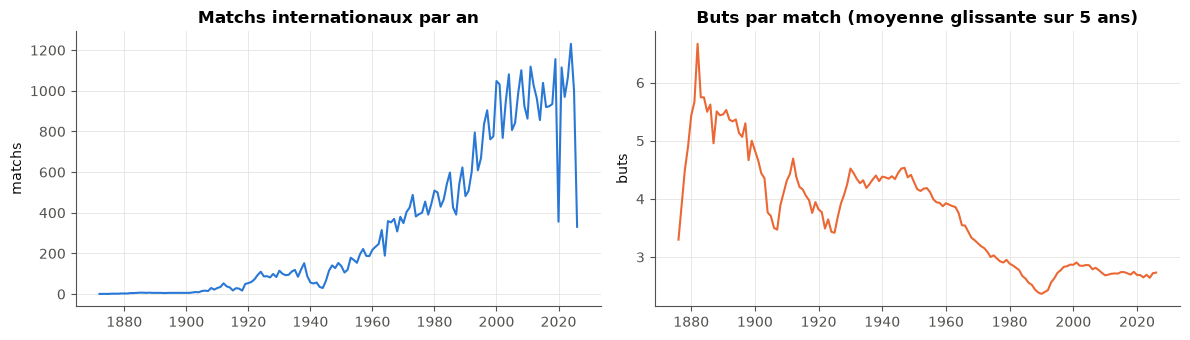

Buts par match depuis 2000 : 2.76


In [4]:
h = historique_raw.assign(annee=historique_raw.date.dt.year, buts=historique_raw.home_score + historique_raw.away_score)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
h.groupby("annee").size().plot(ax=ax[0], color=BLEU)
ax[0].set(title="Matchs internationaux par an", xlabel="", ylabel="matchs")
h.groupby("annee").buts.mean().rolling(5).mean().plot(ax=ax[1], color=ORANGE)
ax[1].set(title="Buts par match (moyenne glissante sur 5 ans)", xlabel="", ylabel="buts")
plt.tight_layout(); plt.show()
print(f"Buts par match depuis 2000 : {h[h.annee >= 2000].buts.mean():.2f}")

## 2.2 Avantage du terrain et part de matchs nuls

In [5]:
def issues(df):
    return pd.Series({"Victoire équipe 1": (df.home_score > df.away_score).mean(),
                      "Nul": (df.home_score == df.away_score).mean(),
                      "Victoire équipe 2": (df.home_score < df.away_score).mean(),
                      "matchs": len(df)})
recent = historique_raw[historique_raw.date >= "2000-01-01"]
tab = pd.DataFrame({"À domicile": issues(recent[~recent.neutral]),
                    "Terrain neutre": issues(recent[recent.neutral]),
                    "Coupe du monde (phase finale)": issues(recent[recent.tournament == "FIFA World Cup"])}).T
tab["matchs"] = tab["matchs"].astype(int)
tab.style.format({c: "{:.1%}" for c in tab.columns[:3]})

,Victoire équipe 1,Nul,Victoire équipe 2,matchs
À domicile,50.8%,23.1%,26.1%,18139
Terrain neutre,41.6%,23.7%,34.8%,7270
Coupe du monde (phase finale),43.5%,22.9%,33.6%,384


**Lecture**
- À domicile, l'équipe qui reçoit gagne environ 1 match sur 2 ; sur terrain neutre, l'« équipe 1 » n'a presque plus d'avantage. L'**avantage du terrain** est donc réel et doit figurer dans le modèle (c'est le `+100` points Elo du notebook).
- Environ **un match sur quatre est nul**. Un classifieur qui choisit toujours l'issue la plus probable ne prédira presque **jamais** de nul. C'est pourquoi on jugera les modèles sur leurs **probabilités** (log-loss, RPS), et pas seulement sur l'accuracy.
- Presque tous les matchs de Coupe du monde sont joués sur terrain neutre, sauf ceux des pays hôtes.

## 2.3 Le nombre de buts suit-il une loi de Poisson ?

Le notebook simule les scores avec une **loi de Poisson** : une loi qui compte des événements rares et indépendants, avec une seule valeur (la moyenne λ). Une propriété simple à vérifier : pour une loi de Poisson, **la variance est égale à la moyenne**.

Buts d'une équipe dans un match (depuis 2000) : moyenne 1.38 | variance 2.45


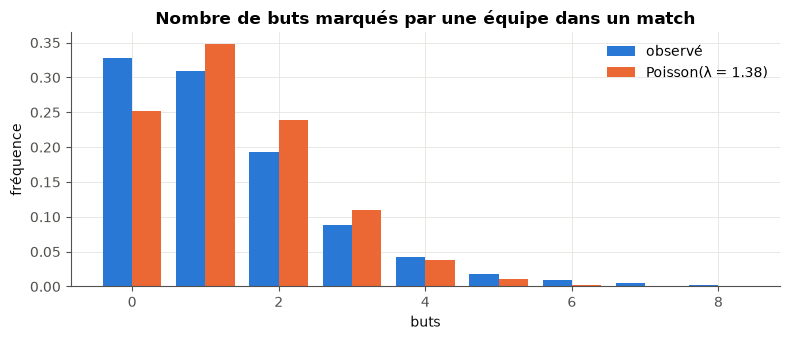

In [6]:
buts = pd.concat([recent.home_score, recent.away_score])
lam = buts.mean()
print(f"Buts d'une équipe dans un match (depuis 2000) : moyenne {lam:.2f} | variance {buts.var():.2f}")
k = np.arange(0, 9)
obs = buts.value_counts(normalize=True).reindex(k, fill_value=0)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(k - 0.2, obs, width=0.4, color=BLEU, label="observé")
ax.bar(k + 0.2, poisson.pmf(k, lam), width=0.4, color=ORANGE, label=f"Poisson(λ = {lam:.2f})")
ax.set(title="Nombre de buts marqués par une équipe dans un match", xlabel="buts", ylabel="fréquence"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**Lecture** : la variance est plus forte que la moyenne (*surdispersion*), car une Poisson **unique** mélange des matchs déséquilibrés (Allemagne – Saint-Marin) et serrés. Si on fait dépendre λ de l'écart de niveau entre les deux équipes, chaque match a sa propre Poisson et l'ajustement devient bon. C'est l'idée du modèle de buts de la section 5.

## 2.4 Les compétitions

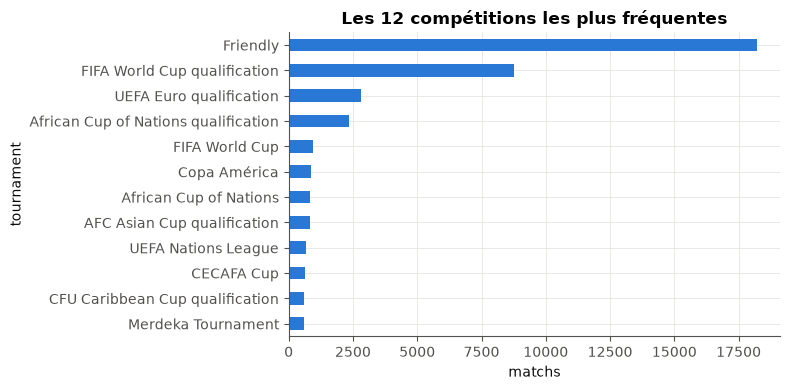

223 compétitions différentes ; amicaux = 37% des matchs


In [7]:
top = historique_raw.tournament.value_counts().head(12)
fig, ax = plt.subplots(figsize=(8, 4))
top.iloc[::-1].plot.barh(ax=ax, color=BLEU)
ax.set(title="Les 12 compétitions les plus fréquentes", xlabel="matchs")
plt.tight_layout(); plt.show()
print(f"{historique_raw.tournament.nunique()} compétitions différentes ; amicaux = {(historique_raw.tournament == 'Friendly').mean():.0%} des matchs")

**Lecture** : plus d'un tiers des matchs sont des **amicaux**, où les équipes font souvent tourner leur effectif. C'est pourquoi l'Elo leur donne un poids plus faible (K = 20 contre 60 pour la Coupe du monde).

## 2.5 Les données joueurs (FC 26 et Transfermarkt)

In [8]:
print("Ligues FC 26 (extrait) :", sorted(fc26_raw.League.dropna().unique())[:8], "…")
print("Ligues féminines présentes :", [l for l in fc26_raw.League.unique() if l in {"Liga F Moeve", "NWSL", "GPFBL", "Barclays WSL", "Arkema PL"}])
print()
print("Transfermarkt — dernière saison jouée par les joueurs :")
print(players_raw.last_season.value_counts().sort_index().tail(12).to_string())
print()
print("Joueurs allemands avec le plus de sélections dans le fichier :")
print(players_raw[players_raw.country_of_citizenship == "Germany"].nlargest(5, "international_caps")[["name", "last_season", "international_caps"]].to_string(index=False))

Ligues FC 26 (extrait) : ['1A Pro League', '3', '3F Superliga', 'A-League', 'Allsvenskan', 'Brack Super League', 'Bundesliga', 'Bundesliga 2'] …
Ligues féminines présentes : ['Liga F Moeve', 'NWSL', 'GPFBL']

Transfermarkt — dernière saison jouée par les joueurs :
last_season
2014     1660
2015     1651
2016     1831
2017     1661
2018     2065
2019     1566
2020     1843
2021     1817
2022     1877
2023     2092
2024     6075
2025    22292

Joueurs allemands avec le plus de sélections dans le fichier :
           name  last_season  international_caps
  Thomas Müller         2025               131.0
 Lukas Podolski         2025               130.0
   Manuel Neuer         2025               128.0
 Joshua Kimmich         2025               114.0
Antonio Rüdiger         2025                86.0


**Lecture**
- FC 26 contient **3 ligues féminines** : `Liga F Moeve`, `NWSL` et `GPFBL` (la Frauen-Bundesliga). Le notebook d'origine n'en filtre que deux.
- Transfermarkt contient **tous les joueurs suivis depuis 2012, y compris les retraités** (Miroslav Klose, dernière saison 2015). Or le notebook calcule l'« expérience » d'une sélection comme la moyenne des sélections (*caps*) de ses 23 joueurs les plus capés **parmi tous les joueurs de cette nationalité**. Risque : juger l'Allemagne sur des joueurs qui ne jouent plus. On vérifie en section 3.4.

## [Prétraitement]

Section 3 — Nettoyage : valeurs manquantes, tri chronologique stable, harmonisation des noms d'équipes, filtrage des joueurs.

---
# 3. Pré-traitement

## 3.1 Les résultats : valeurs manquantes, types et ordre chronologique

In [9]:
print("Valeurs manquantes :", historique_raw.isna().sum().sum())
historique = historique_raw.dropna(subset=["home_score", "away_score"]).copy()
historique[["home_score", "away_score"]] = historique[["home_score", "away_score"]].astype(int)

# L'Elo se calcule match après match : l'ordre compte quand une équipe joue 2 fois le même jour
ordre_instable = historique.sort_values("date").index          # tri par défaut (quicksort : non stable)
ordre_stable   = historique.sort_values("date", kind="stable").index
print(f"Lignes dont la position change selon le tri : {(ordre_instable != ordre_stable).sum():,}")
historique = historique.sort_values("date", kind="stable").reset_index(drop=True)

Valeurs manquantes : 0
Lignes dont la position change selon le tri : 26,481


⚠️ **Correction mineure** : le notebook trie par date avec `sort_values("date")`. Par défaut, pandas utilise un tri **non stable** : les matchs d'un même jour sont mélangés (plus de 26 000 lignes changent de place). L'Elo se calcule dans l'ordre des matchs : l'ordre compte dans les 151 cas où une même équipe joue deux fois le même jour (tournois anciens). On impose donc `kind="stable"`, qui garde l'ordre du fichier.

## 3.2 Les noms d'équipes

Les trois sources n'écrivent pas les pays de la même façon (`Korea Republic`, `Korea, South`, `South Korea`…). On reprend les correspondances du notebook et on **vérifie** que les 48 qualifiés sont bien trouvés.

In [10]:
GROUPS = {
 "A": ["Mexico", "South Africa", "South Korea", "Czech Republic"],
 "B": ["Canada", "Bosnia and Herzegovina", "Qatar", "Switzerland"],
 "C": ["Brazil", "Morocco", "Haiti", "Scotland"],
 "D": ["United States", "Paraguay", "Australia", "Turkey"],
 "E": ["Germany", "Curaçao", "Ivory Coast", "Ecuador"],
 "F": ["Netherlands", "Japan", "Sweden", "Tunisia"],
 "G": ["Belgium", "Egypt", "Iran", "New Zealand"],
 "H": ["Spain", "Cape Verde", "Saudi Arabia", "Uruguay"],
 "I": ["France", "Senegal", "Iraq", "Norway"],
 "J": ["Argentina", "Algeria", "Austria", "Jordan"],
 "K": ["Portugal", "DR Congo", "Uzbekistan", "Colombia"],
 "L": ["England", "Croatia", "Ghana", "Panama"],
}
WC_TEAMS = [t for g in GROUPS.values() for t in g]
GROUP_OF = {t: g for g, ts in GROUPS.items() for t in ts}
HOSTS = {"United States", "Canada", "Mexico"}
CONF = {
 "Mexico": "CONCACAF", "United States": "CONCACAF", "Canada": "CONCACAF", "Panama": "CONCACAF", "Curaçao": "CONCACAF", "Haiti": "CONCACAF",
 "Brazil": "CONMEBOL", "Argentina": "CONMEBOL", "Uruguay": "CONMEBOL", "Colombia": "CONMEBOL", "Paraguay": "CONMEBOL", "Ecuador": "CONMEBOL",
 "Spain": "UEFA", "France": "UEFA", "England": "UEFA", "Portugal": "UEFA", "Netherlands": "UEFA", "Germany": "UEFA", "Belgium": "UEFA",
 "Croatia": "UEFA", "Switzerland": "UEFA", "Austria": "UEFA", "Norway": "UEFA", "Scotland": "UEFA", "Czech Republic": "UEFA",
 "Bosnia and Herzegovina": "UEFA", "Sweden": "UEFA", "Turkey": "UEFA",
 "Morocco": "CAF", "Senegal": "CAF", "Egypt": "CAF", "Ivory Coast": "CAF", "Algeria": "CAF", "Tunisia": "CAF", "Ghana": "CAF",
 "Cape Verde": "CAF", "South Africa": "CAF", "DR Congo": "CAF",
 "Japan": "AFC", "South Korea": "AFC", "Iran": "AFC", "Australia": "AFC", "Saudi Arabia": "AFC", "Qatar": "AFC", "Uzbekistan": "AFC",
 "Jordan": "AFC", "Iraq": "AFC", "New Zealand": "OFC",
}
assert len(WC_TEAMS) == 48 and set(CONF) == set(WC_TEAMS)

FC26_TO_CANON = {"Korea Republic": "South Korea", "Côte d'Ivoire": "Ivory Coast", "Holland": "Netherlands",
                 "Congo DR": "DR Congo", "Cape Verde Islands": "Cape Verde"}
TM_TO_CANON = {"Korea, South": "South Korea", "Bosnia-Herzegovina": "Bosnia and Herzegovina",
               "Cote d'Ivoire": "Ivory Coast", "Congo DR": "DR Congo", "Türkiye": "Turkey"}

noms_resultats = set(historique.home_team) | set(historique.away_team)
print("Qualifiés absents de results.csv :", sorted(set(WC_TEAMS) - noms_resultats))
print("Anciens noms encore présents dans results.csv :", sorted(set(former_names.former) & noms_resultats))

Qualifiés absents de results.csv :

 []
Anciens noms encore présents dans results.csv : []


**Lecture** : les 48 qualifiés sont tous dans `results.csv`. Ce fichier utilise déjà les **noms actuels** des pays (aucun ancien nom de `former_names.csv` n'y figure), donc l'historique de la RD Congo inclut bien celui du Zaïre. Pas de correction nécessaire de ce côté.

## 3.3 FC 26 : garder les joueurs masculins et construire une note globale

FC 26 ne fournit pas de note « Overall ». Le notebook en construit une, **pondérée selon le poste** : un attaquant est jugé sur ses qualités offensives, un défenseur sur ses qualités défensives. C'est un bon choix, on le garde.

In [11]:
ATT6 = ["Pace", "Shooting", "Passing", "Dribbling", "Defending", "Physicality"]
POS_W = {
 "ATT": dict(Pace=.18, Shooting=.30, Passing=.12, Dribbling=.25, Defending=.00, Physicality=.15),
 "WNG": dict(Pace=.18, Shooting=.20, Passing=.20, Dribbling=.27, Defending=.03, Physicality=.12),
 "MID": dict(Pace=.08, Shooting=.15, Passing=.27, Dribbling=.20, Defending=.18, Physicality=.12),
 "DEF": dict(Pace=.16, Shooting=.00, Passing=.14, Dribbling=.05, Defending=.40, Physicality=.25),
}
POS_GROUP = {**{p: "ATT" for p in ["ST", "CF", "LW", "RW"]}, **{p: "WNG" for p in ["LM", "RM", "CAM"]},
             **{p: "MID" for p in ["CM", "CDM"]}, **{p: "DEF" for p in ["CB", "LB", "RB", "LWB", "RWB"]}}

def preparer_fc26(df, ligues_feminines):
    df = df[~df.League.isin(ligues_feminines)].copy()
    for c in ATT6 + ["Reactions", "Composure"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df["canon"] = df.Nation.map(lambda n: FC26_TO_CANON.get(n, n))
    grp = df.Position.map(POS_GROUP).fillna("GK")
    ovr_champ = sum(df[a] * grp.map(lambda g: POS_W.get(g, {}).get(a, 0)) for a in ATT6)
    df["ovr"] = np.where(grp == "GK", df[["Reactions", "Composure"]].mean(axis=1), ovr_champ)   # gardiens : réflexes + sang-froid
    df["atk"] = df[["Shooting", "Dribbling", "Pace", "Passing"]].mean(axis=1)
    df["dfn"] = df[["Defending", "Physicality"]].mean(axis=1)
    return df

fc26_orig = preparer_fc26(fc26_raw, {"Liga F Moeve", "NWSL"})             # filtre du notebook d'origine
fc26 = preparer_fc26(fc26_raw, {"Liga F Moeve", "NWSL", "GPFBL"})          # ⚠️ corrigé : + Frauen-Bundesliga
print(f"FC 26 : {len(fc26_raw):,} joueurs → {len(fc26):,} après filtre (le notebook en gardait {len(fc26_orig):,})")
print("Qualifiés absents de FC 26 :", sorted(set(WC_TEAMS) - set(fc26.canon)))
fc26.nlargest(8, "ovr")[["Name", "Nation", "Position", "ovr"]].round(1)

FC 26 : 16,234 joueurs → 16,228 après filtre (le notebook en gardait 16,229)
Qualifiés absents de FC 26 : ['Qatar']


,Name,Nation,Position,ovr
1,Kylian Mbappé,France,ST,88.6
2,Ousmane Dembélé,France,ST,86.6
17,Vini Jr.,Brazil,LW,85.6
0,Mohamed Salah,Egypt,RM,85.6
5,Jude Bellingham,England,CAM,85.3
40,Julián Alvarez,Argentina,ST,84.7
7,Raphinha,Brazil,LM,84.5
46,Viktor Gyökeres,Sweden,ST,84.4


## 3.4 Transfermarkt : les joueurs retraités faussent-ils l'expérience ?

On compare l'expérience calculée sur tous les joueurs (notebook) et sur les seuls joueurs dont la dernière saison est **2024 ou plus récente**.

In [12]:
players_tm = players_raw.assign(canon=players_raw.country_of_citizenship.map(lambda n: TM_TO_CANON.get(n, n)))
players_actifs = players_tm[players_tm.last_season >= 2024]
nat_teams = nat_teams_raw.assign(canon=nat_teams_raw.country_name.map(lambda n: TM_TO_CANON.get(n, n)))

def experience(players, team):
    s = players.loc[players.canon == team, "international_caps"]
    return s.nlargest(23).mean() if len(s) else np.nan

exp_cmp = pd.DataFrame({"tous les joueurs (notebook)": {t: experience(players_tm, t) for t in WC_TEAMS},
                        "joueurs actifs (corrigé)": {t: experience(players_actifs, t) for t in WC_TEAMS}})
exp_cmp["écart"] = exp_cmp.iloc[:, 0] - exp_cmp.iloc[:, 1]
print(f"Joueurs Transfermarkt : {len(players_tm):,} → {len(players_actifs):,} actifs")
anciens = players_tm[players_tm.last_season < 2024]
print(f"Joueurs retraités ayant un nombre de sélections renseigné : {anciens.international_caps.notna().sum()} sur {len(anciens):,}")
print(f"Écart maximal d'expérience entre les deux calculs : {exp_cmp['écart'].abs().max():.1f} sélection")
print("Qualifiés absents de Transfermarkt :", sorted(set(WC_TEAMS) - set(nat_teams.canon)))
exp_cmp.sort_values("écart", ascending=False).head(8).round(1)

Joueurs Transfermarkt : 50,149 → 28,367 actifs
Joueurs retraités ayant un nombre de sélections renseigné : 0 sur 21,782
Écart maximal d'expérience entre les deux calculs : 0.0 sélection
Qualifiés absents de Transfermarkt : ['Cape Verde', 'Curaçao', 'DR Congo', 'Haiti', 'Ivory Coast']


,tous les joueurs (notebook),joueurs actifs (corrigé),écart
Mexico,88.9,88.9,0.0
Argentina,75.0,75.0,0.0
New Zealand,41.0,41.0,0.0
Spain,67.8,67.8,0.0
Cape Verde,38.4,38.4,0.0
Saudi Arabia,56.9,56.9,0.0
Uruguay,61.7,61.7,0.0
France,72.2,72.2,0.0


**Lecture** : **fausse alerte**. Dans ce fichier, les joueurs retraités n'ont **pas** de nombre de sélections renseigné (la colonne est vide), donc ils ne comptent pas dans le calcul. Les deux calculs donnent exactement le même résultat : le code d'origine est correct sur ce point, on le garde tel quel.

Il reste une limite de fond, que l'on note sans pouvoir la corriger : « actif en club » ne veut pas dire « sélectionné ». Lukas Podolski (130 sélections, toujours en activité en Pologne) compte encore dans l'expérience de l'Allemagne alors qu'il a quitté la sélection en 2017.

## [Transformation]

Section 4 — Construction des variables : classement Elo, variables d'avant-match, variables par équipe, table d'apprentissage.

---
# 4. Transformation

## 4.1 Le classement Elo et les variables d'avant-match

L'Elo donne à chaque équipe une note qui évolue après chaque match :

$$R' = R + K \cdot G \cdot (W - W_e), \qquad W_e = \frac{1}{1 + 10^{-(R_1 - R_2 + H)/400}}$$

- $W$ : le résultat (1 victoire, 0,5 nul, 0 défaite) ; $W_e$ : le résultat **attendu**, d'après l'écart de notes ;
- $K$ : l'importance du match (60 en Coupe du monde, 20 en amical) ; $G$ : un bonus quand l'écart de buts est large ; $H$ : l'avantage du terrain (+100 points, 0 sur terrain neutre).

C'est l'étape clé du projet : elle transforme une liste de scores en **variables numériques**. Pour chaque match, on enregistre l'état **avant** le coup d'envoi : notes Elo, mais aussi forme récente, buts marqués et encaissés sur les 10 derniers matchs, et nombre de matchs joués. Le résultat du match n'est utilisé **qu'après** pour mettre à jour les notes, donc **aucune fuite d'information**.

Le calcul est **séquentiel** par nature : chaque match dépend de tous les précédents. On ne peut pas le paralléliser naïvement. Ce point sera intéressant à garder en tête pour le TP3_big avec Spark.

In [13]:
def k_factor(t):
    t = str(t).lower()
    if "world cup" in t and "qualif" not in t: return 60
    if "confederations" in t: return 50
    if any(x in t for x in ["uefa euro", "copa am", "african cup", "afc asian", "gold cup", "nations league"]): return 40
    if "qualif" in t: return 40
    if "friendly" in t: return 20
    return 30

def g_mult(gd):
    gd = abs(gd)
    return 1.0 if gd <= 1 else (1.5 if gd == 2 else (11 + gd) / 8)

HOME_ADV = 100
N_FORME = 10

class EtatElo:
    "Tout ce que l'on sait des équipes à un instant donné."
    def __init__(self):
        self.elo, self.n, self.hist = {}, defaultdict(int), defaultdict(list)
        self.pts, self.bp, self.bc = (defaultdict(lambda: deque(maxlen=N_FORME)) for _ in range(3))
    def note(self, t): return self.elo.get(t, 1500.0)
    def moy(self, d, t): return np.mean(d[t]) if d[t] else np.nan

def calcul_elo(matchs, home_adv=HOME_ADV, k_scale=1.0, etat=None):
    "Parcourt les matchs dans l'ordre ; renvoie les variables d'avant-match et l'état final."
    e = etat or EtatElo()
    lignes = []
    for r in matchs.itertuples(index=False):
        h, a = r.home_team, r.away_team
        Rh, Ra = e.note(h), e.note(a)
        ha = 0 if r.neutral else home_adv
        lignes.append((r.date, h, a, r.tournament, Rh, Ra, ha, h in e.elo and a in e.elo,
                       e.moy(e.pts, h), e.moy(e.pts, a), e.moy(e.bp, h), e.moy(e.bc, h),
                       e.moy(e.bp, a), e.moy(e.bc, a), e.n[h], e.n[a], r.home_score, r.away_score))
        # --- mise à jour APRÈS avoir enregistré l'état d'avant-match
        We = 1 / (1 + 10 ** (-((Rh - Ra) + ha) / 400))
        Wh = 1.0 if r.home_score > r.away_score else (0.5 if r.home_score == r.away_score else 0.0)
        d = k_scale * k_factor(r.tournament) * g_mult(r.home_score - r.away_score) * (Wh - We)
        e.elo[h], e.elo[a] = Rh + d, Ra - d
        for t, bp, bc, w in [(h, r.home_score, r.away_score, Wh), (a, r.away_score, r.home_score, 1 - Wh)]:
            e.pts[t].append(w); e.bp[t].append(bp); e.bc[t].append(bc); e.n[t] += 1
            e.hist[t].append((r.date, e.elo[t]))
    cols = ["date", "home", "away", "tournament", "Rh", "Ra", "ha", "connues", "forme_h", "forme_a",
            "bp_h", "bc_h", "bp_a", "bc_a", "n_h", "n_a", "hs", "as_"]
    return pd.DataFrame(lignes, columns=cols), e

t0 = time.perf_counter()
avant_match, ETAT = calcul_elo(historique)
print(f"Elo calculé sur {len(avant_match):,} matchs en {time.perf_counter() - t0:.1f} s | {len(ETAT.elo)} équipes notées")
print("\nTop 10 des qualifiés au coup d'envoi :")
print(pd.Series({t: round(ETAT.note(t)) for t in WC_TEAMS}).sort_values(ascending=False).head(10).to_string())

Elo calculé sur 49,475 matchs en 1.6 s | 337 équipes notées

Top 10 des qualifiés au coup d'envoi :
Spain          2203
Argentina      2179
France         2126
England        2085
Brazil         2066
Colombia       2055
Portugal       2048
Ecuador        2023
Netherlands    2009
Germany        2002


## 4.2 L'Elo prédit-il les résultats ? Ses réglages sont-ils bons ?

On reprend la validation du notebook (taux de victoire par tranche d'écart Elo). Puis on vérifie que les deux réglages choisis par l'auteur, **H = 100** et l'échelle de **K**, sont pertinents. Pour cela, on teste plusieurs valeurs et on garde celle qui prédit le mieux les matchs de **2015-2020** (période de validation), avec un modèle entraîné sur 2000-2014. La période de test (2021-2026) n'est pas utilisée ici.

In [14]:
v = avant_match[(avant_match.date >= "2015-01-01") & avant_match.connues].copy()
v["ecart"] = v.Rh - v.Ra + v.ha
v["victoire_1"] = (v.hs > v.as_).astype(int)
print(v.groupby(pd.cut(v.ecart, [-1000, -200, -100, 0, 100, 200, 1000]), observed=True).victoire_1.mean().round(3).to_string())

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, accuracy_score

def cible(hs, as_): return np.select([hs > as_, hs == as_], [2, 1], 0)    # 2 = victoire équipe 1, 1 = nul, 0 = défaite

grille = []
for ha_, ks in itertools.product([50, 100, 150], [0.75, 1.0, 1.5]):
    am, _ = calcul_elo(historique, home_adv=ha_, k_scale=ks)
    am = am[am.connues]
    X = np.c_[am.Rh - am.Ra + am.ha, (am.Rh + am.Ra) / 2] / 100
    y = cible(am.hs, am.as_)
    tr = (am.date >= "2000-01-01") & (am.date < "2015-01-01"); va = (am.date >= "2015-01-01") & (am.date < "2021-01-01")
    m = LogisticRegression(max_iter=2000).fit(X[tr], y[tr])
    grille.append({"H (avantage terrain)": ha_, "échelle de K": ks, "log-loss validation": log_loss(y[va], m.predict_proba(X[va]))})
grille = pd.DataFrame(grille).pivot(index="H (avantage terrain)", columns="échelle de K", values="log-loss validation")
grille.round(4)

ecart
(-1000, -200]    0.095
(-200, -100]     0.196
(-100, 0]        0.306
(0, 100]         0.412
(100, 200]       0.542
(200, 1000]      0.760


échelle de K,0.75,1.00,1.50
H (avantage terrain),,,
50,0.8932,0.8920,0.8932
100,0.8922,0.8907,0.8915
150,0.8950,0.8928,0.8926


**Lecture**
- Plus l'écart Elo est grand, plus l'équipe 1 gagne souvent : de 10 % à 76 % selon l'écart. L'Elo est un bon prédicteur.
- La grille confirme les réglages de l'auteur : **H = 100 et K × 1** sont au minimum de la log-loss, ou à moins de 0,001 de ce minimum. On les garde. C'est un résultat utile : il n'y a pas de gain facile à aller chercher dans le réglage de l'Elo.

## 4.3 Les tirs au but : le favori a-t-il un avantage ?

Lors d'un match à élimination directe, un nul mène aux tirs au but. Le notebook donne alors la qualification au favori **selon son Elo**. On vérifie sur les 690 séances historiques.

In [15]:
notes_avant = avant_match.set_index(["date", "home", "away"])[["Rh", "Ra"]]
so = shootouts[shootouts.date < WC2026_START].join(notes_avant, on=["date", "home_team", "away_team"], how="inner")
favori = np.where(so.Rh >= so.Ra, so.home_team, so.away_team)
print(f"{len(so)} séances : le favori Elo gagne {np.mean(favori == so.winner):.1%} des tirs au but")
print(f"Probabilité qu'aurait donnée la formule Elo au favori, en moyenne : {np.mean(1 / (1 + 10 ** (-abs(so.Rh - so.Ra) / 400))):.1%}")

690 séances : le favori Elo gagne 53.0% des tirs au but
Probabilité qu'aurait donnée la formule Elo au favori, en moyenne : 64.6%


**Lecture** : les tirs au but sont **presque une loterie**. Le favori les gagne à peine plus d'une fois sur deux, alors que la formule Elo lui donnerait une probabilité nettement plus élevée. ⚠️ Le notebook surestime donc les chances des favoris dans les matchs nuls à élimination directe. Dans notre modèle amélioré, une séance de tirs au but sera un **50/50**.

## 4.4 Les variables par équipe et la couche « facteurs »

Pour les 48 qualifiés, le notebook calcule des indicateurs d'effectif (FC 26 et Transfermarkt), puis les transforme en un **ajustement Elo** : une somme pondérée des indicateurs centrés-réduits (*z-scores*), multipliée par 42 et plafonnée à **±60 points**. Les poids sont choisis à la main. On calcule ces variables deux fois, avec le filtre des ligues féminines d'origine puis avec le filtre complet. La seule joueuse retirée en plus ne change presque rien, mais on garde les deux versions pour reproduire fidèlement le modèle de l'auteur.

In [16]:
TOP5 = {"Premier League", "LALIGA EA SPORTS", "Serie A Enilive", "Bundesliga", "Ligue 1 McDonald's"}
ATK_POS = {"ST", "LW", "RW", "CAM", "LM", "RM", "CF"}; DEF_POS = {"CB", "LB", "RB", "CDM", "LWB", "RWB"}
DERNIER_JOUR = historique.date.max()

def elo_trend(t, mois=24):
    h = ETAT.hist.get(t, [])
    if not h: return 0.0
    cut = DERNIER_JOUR - pd.Timedelta(days=30 * mois); past = [v for d, v in h if d <= cut]
    return h[-1][1] - (past[-1] if past else h[0][1])

wc_hist = historique[historique.tournament == "FIFA World Cup"]
def wc_pedigree(t):
    m = wc_hist[(wc_hist.home_team == t) | (wc_hist.away_team == t)]
    if len(m) == 0: return 0.0, 0
    v = ((m.home_team == t) & (m.home_score > m.away_score)) | ((m.away_team == t) & (m.away_score > m.home_score))
    return v.mean(), len(m)

def variables_equipes(fc, players):
    lignes = []
    for t in WC_TEAMS:
        sub = fc[fc.canon == t]; best = sub.nlargest(23, "ovr")
        wr, wm = wc_pedigree(t)
        lignes.append(dict(team=t, elo=ETAT.note(t), elo_trend=elo_trend(t), wc_winrate=wr, wc_matches=wm,
            squad_rating=best.ovr.mean(), star_rating=sub.ovr.max(), top3_rating=sub.nlargest(3, "ovr").ovr.mean(),
            star_dependency=sub.ovr.max() - best.ovr.mean(), squad_depth=(sub.ovr >= 75).sum(),
            top5_league_pct=100 * best.League.isin(TOP5).mean() if len(best) else np.nan,
            exp_caps=experience(players, t)))
    f = pd.DataFrame(lignes)
    for c in f.columns[5:]:
        f[c] = f[c].fillna(f[c].median())          # équipes peu couvertes (Qatar…) : valeur médiane
    return f

W_FACTEURS = {"squad_rating": .26, "top5_league_pct": .20, "top3_rating": .16, "exp_caps": .12,
              "wc_winrate": .12, "elo_trend": .08, "squad_depth": .06, "star_dependency": -.10}
def ajustement(f, scale=42, cap=60, poids=W_FACTEURS):
    z = lambda s: (s - s.mean()) / (s.std(ddof=0) + 1e-9)
    indice = sum(z(f[k].astype(float)) * w for k, w in poids.items())
    return dict(zip(f.team, (scale * indice).clip(-cap, cap)))

feat_orig = variables_equipes(fc26_orig, players_tm)
feat = variables_equipes(fc26, players_tm)
ADJ_ORIG, ADJ = ajustement(feat_orig), ajustement(feat)
cmp = pd.DataFrame({"Elo": feat.set_index("team").elo, "ajust. origine": pd.Series(ADJ_ORIG), "ajust. corrigé": pd.Series(ADJ)})
cmp.sort_values("Elo", ascending=False).head(12).round(1)

,Elo,ajust. origine,ajust. corrigé
Spain,2203.0,60.0,60.0
Argentina,2179.1,41.4,41.3
France,2126.4,60.0,60.0
England,2085.4,56.6,56.5
Brazil,2065.6,58.7,58.6
Colombia,2055.0,21.2,21.2
Portugal,2047.7,40.1,40.1
Ecuador,2022.8,-8.9,-8.9
Netherlands,2008.9,42.5,42.5
Germany,2002.2,60.0,60.0


## 4.5 La table d'apprentissage

Chaque match de l'historique devient une ligne : des **variables d'avant-match** et une **cible** à 3 classes (défaite / nul / victoire de l'équipe 1).

| Variable | Sens |
|---|---|
| `ecart` | écart Elo + avantage du terrain |
| `elo_moyen` | niveau moyen des deux équipes (un match entre grandes nations est plus serré) |
| `neutre`, `competitif`, `coupe_monde` | contexte du match |
| `forme_diff` | différence de points pris sur les 10 derniers matchs |
| `attaque_diff`, `defense_diff` | différence de buts marqués / encaissés sur les 10 derniers matchs |
| `experience` | log du nombre de matchs joués par l'équipe la moins expérimentée |

On garde les matchs depuis 2005 (comme le notebook) entre deux équipes déjà notées.

In [17]:
def ajouter_variables(m):
    m = m.copy()
    m["ecart"] = m.Rh - m.Ra + m.ha
    m["ecart_brut"] = m.Rh - m.Ra
    m["elo_moyen"] = (m.Rh + m.Ra) / 2
    m["neutre"] = (m.ha == 0).astype(int)
    k = m.tournament.map(k_factor)
    m["competitif"] = (k >= 40).astype(int)
    m["coupe_monde"] = (k == 60).astype(int)
    m["forme_diff"] = m.forme_h - m.forme_a
    m["attaque_diff"] = m.bp_h - m.bp_a
    m["defense_diff"] = m.bc_h - m.bc_a
    m["experience"] = np.log1p(np.minimum(m.n_h, m.n_a))
    m["y"] = cible(m.hs, m.as_)
    return m

VARS_ORIG = ["ecart_brut", "ha", "elo_moyen"]                       # les 3 variables du notebook
VARS = ["ecart", "elo_moyen", "neutre", "competitif", "coupe_monde",
        "forme_diff", "attaque_diff", "defense_diff", "experience"]

table = ajouter_variables(avant_match)
table = table[(table.date >= "2005-01-01") & table.connues].dropna(subset=VARS).reset_index(drop=True)
print(f"Table d'apprentissage : {len(table):,} matchs × {len(VARS)} variables")
print("Répartition de la cible :", table.y.map({0: "défaite", 1: "nul", 2: "victoire"}).value_counts(normalize=True).round(3).to_dict())

Table d'apprentissage : 20,468 matchs × 9 variables
Répartition de la cible : {'victoire': 0.479, 'défaite': 0.288, 'nul': 0.232}


## [ML]

Section 5 — Reproduction des modèles du notebook d'origine, puis deux améliorations.

---
# 5. Machine Learning

## 5.1 Découpage et métriques

**Découpage chronologique** : on apprend sur le passé et on teste sur le futur, comme en situation réelle.
- **Apprentissage** : 2005 → 2020 ;
- **Test** : 2021 → 10 juin 2026 (plus de 5 000 matchs jamais vus).

Le notebook d'origine coupe à 80 % des lignes, ce qui revient à peu près au même ; on fixe une date pour que ce soit lisible.

**Trois métriques**, car prédire un match de football, c'est donner des **probabilités** :

| Métrique | Ce qu'elle mesure | Référence |
|---|---|---|
| **Accuracy** | % de matchs où l'issue la plus probable est la bonne | plus haut = mieux |
| **Log-loss** | pénalise fortement une probabilité faible donnée à ce qui arrive | plus bas = mieux ; 1,05 = probabilités au hasard pondéré |
| **RPS** (*Ranked Probability Score*) | écart entre probabilités cumulées et résultat, **en tenant compte de l'ordre** défaite < nul < victoire | plus bas = mieux ; la métrique de référence en football |

Avec le RPS, prédire « victoire » quand le match finit nul coûte moins cher que quand il finit en défaite.

In [18]:
def rps(P, y):
    "Ranked Probability Score, P en colonnes [défaite, nul, victoire]."
    O = np.eye(3)[np.asarray(y)]
    return np.mean(np.sum((np.cumsum(P, 1) - np.cumsum(O, 1))[:, :2] ** 2, axis=1) / 2)

def scores(nom, P, y):
    y = np.asarray(y)
    return {"modèle": nom, "accuracy": accuracy_score(y, P.argmax(1)), "log-loss": log_loss(y, P, labels=[0, 1, 2]),
            "RPS": rps(P, y), "% nuls prédits": np.mean(P.argmax(1) == 1)}

COUPURE = pd.Timestamp("2021-01-01")
train, test = table[table.date < COUPURE], table[table.date >= COUPURE]
y_tr, y_te = train.y.values, test.y.values
print(f"Apprentissage : {len(train):,} matchs | test : {len(test):,} matchs")

RESULTATS_ML = [scores("Référence : fréquences d'apprentissage", np.tile(np.bincount(y_tr) / len(y_tr), (len(test), 1)), y_te)]

Apprentissage : 14,764 matchs | test : 5,704 matchs


## 5.2 Reproduction des modèles du notebook

On reprend les 3 modèles de l'auteur (régression logistique, Random Forest, XGBoost) avec les mêmes 3 variables.

In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Le code d'origine :
try:
    LogisticRegression(max_iter=1000, multi_class="multinomial").fit(train[VARS_ORIG], y_tr)
except TypeError as e:
    print("⚠️ Erreur du code d'origine :", e)

⚠️ Erreur du code d'origine : LogisticRegression.__init__() got an unexpected keyword argument 'multi_class'


⚠️ **Correction n°1** : le paramètre `multi_class` a été **supprimé** de scikit-learn (déprécié en 1.5, retiré en 1.8). Le notebook ne s'exécute plus tel quel. Depuis la version 1.5, la régression logistique est multinomiale par défaut avec 3 classes : il suffit de retirer le paramètre.

⚠️ **Correction n°2** : le notebook appelle son `StandardScaler` `sc`, le nom qu'on utilise pour le `SparkContext` dans nos TP Spark. On utilise ici un **pipeline** scikit-learn (normalisation + modèle), qui évite la variable séparée et garantit que la normalisation est apprise **uniquement** sur l'apprentissage.

In [20]:
modeles_orig = {
    "LR (3 variables)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest (3 variables)": RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=50, random_state=SEED, n_jobs=-1),
    "XGBoost (3 variables)": XGBClassifier(n_estimators=350, max_depth=4, learning_rate=.05, subsample=.9, colsample_bytree=.9,
                                           random_state=SEED, n_jobs=-1),
}
for nom, m in modeles_orig.items():
    m.fit(train[VARS_ORIG], y_tr)
    RESULTATS_ML.append(scores(nom, m.predict_proba(test[VARS_ORIG]), y_te))
pd.DataFrame(RESULTATS_ML).set_index("modèle").round(4)

,accuracy,log-loss,RPS,% nuls prédits
modèle,,,,
Référence : fréquences d'apprentissage,0.4797,1.0492,0.2281,0.0000
LR (3 variables),0.6097,0.8593,0.1670,0.0000
Random Forest (3 variables),0.6097,0.8673,0.1682,0.0000
XGBoost (3 variables),0.6055,0.8677,0.1683,0.0102


**Lecture** : on retrouve les résultats de l'auteur, environ **61 % d'accuracy**. Les 3 modèles se valent, Random Forest et XGBoost étant même un peu moins bons en log-loss. C'est logique : les 3 variables se résument presque à **une seule** (l'écart Elo), et le lien entre écart et résultat est simple et régulier. Une régression logistique suffit, des arbres n'apportent rien. Aucun modèle ne prédit de nul (0 %).

## 5.3 Amélioration n°1 : plus de variables, modèles mieux réglés

On donne aux modèles les 9 variables de la section 4.5. Pour le gradient boosting, on choisit les hyperparamètres par **validation croisée temporelle** (`TimeSeriesSplit`) : chaque pli apprend sur le passé et valide sur la période suivante, sans jamais regarder le test.

In [21]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.ensemble import HistGradientBoostingClassifier

lr9 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(train[VARS], y_tr)
RESULTATS_ML.append(scores("LR (9 variables)", lr9.predict_proba(test[VARS]), y_te))

t0 = time.perf_counter()
gs = GridSearchCV(HistGradientBoostingClassifier(random_state=SEED),
                  {"max_depth": [2, 3, 4], "learning_rate": [0.03, 0.06], "max_iter": [200, 400], "l2_regularization": [0.0, 1.0]},
                  scoring="neg_log_loss", cv=TimeSeriesSplit(n_splits=4), n_jobs=-1).fit(train[VARS], y_tr)
hgb = gs.best_estimator_
print(f"Meilleurs hyperparamètres ({time.perf_counter() - t0:.0f} s) :", gs.best_params_)
RESULTATS_ML.append(scores("Gradient Boosting réglé (9 variables)", hgb.predict_proba(test[VARS]), y_te))

coefs = pd.Series(lr9[-1].coef_[2] - lr9[-1].coef_[0], index=VARS).sort_values()
print("\nEffet de chaque variable (LR, victoire vs défaite, variables centrées-réduites) :")
print(coefs.round(3).to_string())

Meilleurs hyperparamètres (8 s) : {'l2_regularization': 0.0, 'learning_rate': 0.03, 'max_depth': 2, 'max_iter': 200}

Effet de chaque variable (LR, victoire vs défaite, variables centrées-réduites) :
defense_diff   -0.386
forme_diff     -0.329
elo_moyen      -0.073
neutre         -0.038
experience     -0.018
coupe_monde     0.010
competitif      0.019
attaque_diff    0.083
ecart           1.682


**Lecture**
- Passer de 3 à 9 variables **n'améliore presque rien** : RPS 0,1670 → 0,1661. Le gradient boosting réglé choisit des arbres de **profondeur 2**, signe que la relation est presque linéaire.
- L'**écart Elo** écrase tout (coefficient 1,68). Les autres effets sont faibles. À Elo égal, une équipe qui **encaisse beaucoup** gagne moins souvent (`defense_diff` < 0). Une équipe en **grande forme** récente gagne un peu *moins* que prévu (`forme_diff` < 0) : sa forme est déjà comptée dans son Elo, et elle a tendance à revenir à son niveau moyen.
- **Conclusion** : l'information contenue dans les résultats passés est déjà résumée par l'Elo. Le football est très aléatoire : même un modèle parfait ne dépasserait pas de beaucoup 60 % d'accuracy. Pour progresser, il faut de **nouvelles informations** (composition des effectifs) plutôt qu'un modèle plus complexe. On le vérifiera en section 7.

## 5.4 Amélioration n°2 : un modèle de buts cohérent (Poisson + Dixon-Coles)

Le notebook utilise **deux modèles différents** :
- un **classifieur** pour les probabilités victoire/nul/défaite des matchs de poule ;
- une **loi de Poisson** pour le score prédit et pour la simulation du tournoi.

⚠️ **Correction n°3** : ces deux modèles peuvent se contredire. Le notebook affiche par exemple Espagne – France : « vainqueur prédit : Espagne », mais « score prédit : 1-1 » (section 5.6). De plus, la Poisson est ajustée par une **régression linéaire sur `log(buts + 0,5)`**, une approximation biaisée.

**Notre modèle** : une seule loi décrit le match.
1. Une **régression de Poisson** (`PoissonRegressor`, la vraie méthode du maximum de vraisemblance) prédit le nombre de buts attendu λ de chaque équipe. Les variables : écart Elo, avantage du terrain, niveau moyen, contexte, attaque de l'équipe et défense de l'adversaire, forme.
2. La **correction de Dixon-Coles** (paramètre ρ) ajuste les petits scores (0-0, 1-0, 0-1, 1-1). Les deux Poisson indépendantes sous-estiment légèrement les nuls ; ρ est choisi sur les dernières années de l'apprentissage.
3. De la matrice des scores, on déduit **tout le reste** : P(victoire), P(nul), P(défaite), le score le plus probable, et les tirages aléatoires de la simulation.

In [22]:
from sklearn.linear_model import PoissonRegressor
VARS_BUTS = ["ecart_brut", "ha", "elo_moyen", "competitif", "attaque", "defense_adv", "forme"]

def vue_equipe(m):
    "Deux lignes par match : les buts de l'équipe 1, puis ceux de l'équipe 2 (chacune vue comme « attaquante »)."
    c = m.competitif if "competitif" in m else (m.tournament.map(k_factor) >= 40).astype(int)
    e1 = pd.DataFrame({"ecart_brut": m.Rh - m.Ra, "ha": m.ha, "elo_moyen": (m.Rh + m.Ra) / 2, "competitif": c,
                       "attaque": m.bp_h, "defense_adv": m.bc_a, "forme": m.forme_h - m.forme_a, "buts": m.hs})
    e2 = pd.DataFrame({"ecart_brut": m.Ra - m.Rh, "ha": -m.ha, "elo_moyen": (m.Rh + m.Ra) / 2, "competitif": c,
                       "attaque": m.bp_a, "defense_adv": m.bc_h, "forme": m.forme_a - m.forme_h, "buts": m.as_})
    return e1, e2

e1, e2 = vue_equipe(train)
modele_buts = make_pipeline(StandardScaler(), PoissonRegressor(alpha=1e-4, max_iter=1000))
modele_buts.fit(pd.concat([e1, e2])[VARS_BUTS], pd.concat([e1, e2]).buts)

def lambdas(m):
    e1, e2 = vue_equipe(m)
    return modele_buts.predict(e1[VARS_BUTS]), modele_buts.predict(e2[VARS_BUTS])

BUTS_MAX = 10
def matrice_scores(l1, l2, rho):
    "Matrice P(score = i-j) avec la correction de Dixon-Coles sur les petits scores."
    g = np.arange(BUTS_MAX + 1)
    M = np.outer(poisson.pmf(g, l1), poisson.pmf(g, l2))
    # facteurs bornés à 0 : la correction n'a de sens que pour des λ modérés
    M[0, 0] *= max(1 - l1 * l2 * rho, 0); M[0, 1] *= max(1 + l1 * rho, 0); M[1, 0] *= max(1 + l2 * rho, 0); M[1, 1] *= max(1 - rho, 0)
    return M / M.sum()

def proba_issues(l1, l2, rho):
    out = np.empty((len(l1), 3))
    for i, (a, b) in enumerate(zip(l1, l2)):
        M = matrice_scores(a, b, rho)
        out[i] = [np.triu(M, 1).sum(), np.trace(M), np.tril(M, -1).sum()]     # [défaite, nul, victoire]
    return out

# Choix de rho sur 2017-2020 (fin de l'apprentissage), modèle appris sur 2005-2016
fin = train.date >= "2017-01-01"
e1, e2 = vue_equipe(train[~fin])
mb_tmp = make_pipeline(StandardScaler(), PoissonRegressor(alpha=1e-4, max_iter=1000)).fit(pd.concat([e1, e2])[VARS_BUTS], pd.concat([e1, e2]).buts)
v1, v2 = vue_equipe(train[fin]); l1v, l2v = mb_tmp.predict(v1[VARS_BUTS]), mb_tmp.predict(v2[VARS_BUTS])
choix_rho = {rho: log_loss(train[fin].y, proba_issues(l1v, l2v, rho), labels=[0, 1, 2]) for rho in [0, -0.05, -0.1, -0.15, -0.2]}
RHO = min(choix_rho, key=choix_rho.get)
print("log-loss selon rho :", {k: round(v, 4) for k, v in choix_rho.items()}, "→ rho =", RHO)

l1_te, l2_te = lambdas(test)
RESULTATS_ML.append(scores("Poisson + Dixon-Coles (notre modèle)", proba_issues(l1_te, l2_te, RHO), y_te))

# Pour comparaison : la Poisson du notebook (régression linéaire sur log(buts + 0,5))
dh = (train.Rh - train.Ra) + train.ha; da = (train.Ra - train.Rh) - train.ha
B1, B0 = np.polyfit(np.r_[dh, da] / 100, np.log(np.r_[train.hs, train.as_] + 0.5), 1)
def exp_goals_orig(d): return np.maximum(0.15, np.exp(B0 + B1 * np.asarray(d) / 100))
RESULTATS_ML.append(scores("Poisson du notebook (polyfit)",
                           proba_issues(exp_goals_orig(test.Rh - test.Ra + test.ha), exp_goals_orig(test.Ra - test.Rh - test.ha), 0), y_te))
print(f"Buts moyens réels (test) : {test.hs.mean():.2f} – {test.as_.mean():.2f} | "
      f"notre modèle : {l1_te.mean():.2f} – {l2_te.mean():.2f} | "
      f"notebook : {exp_goals_orig(test.Rh - test.Ra + test.ha).mean():.2f} – {exp_goals_orig(test.Ra - test.Rh - test.ha).mean():.2f}")

log-loss selon rho : {0: 0.8955, -0.05: 0.8944, -0.1: 0.894, -0.15: 0.8943, -0.2: 0.8952} → rho = -0.1


Buts moyens réels (test) : 1.61 – 1.11 | notre modèle : 1.64 – 1.11 | notebook : 1.70 – 1.29


**Lecture**
- La régression de Poisson atteint la **même qualité que la meilleure régression logistique** (RPS 0,1662 contre 0,1661), mais elle donne **en plus** les scores, ce qu'un classifieur ne sait pas faire.
- La correction de Dixon-Coles (ρ = −0,1) améliore légèrement la log-loss : elle remonte un peu la probabilité des 0-0 et 1-1.
- La Poisson du notebook (polyfit) est la moins bonne (RPS 0,1692) et **surestime les buts** : 1,70 – 1,29 prédits contre 1,61 – 1,11 réels, soit +16 % pour l'équipe 2. Ce biais se retrouve dans toutes ses simulations.

## [Éval]

Section 6 — Évaluation classique sur le jeu de test (2021 – juin 2026) : comparaison des modèles et calibration.

---
# 6. Évaluation classique (test 2021 – juin 2026)

## 6.1 Tableau comparatif

In [23]:
res_ml = pd.DataFrame(RESULTATS_ML).set_index("modèle")
res_ml.style.format({"accuracy": "{:.3f}", "log-loss": "{:.4f}", "RPS": "{:.4f}", "% nuls prédits": "{:.1%}"}) \
      .highlight_min(subset=["log-loss", "RPS"], color="#d4f1e4").highlight_max(subset=["accuracy"], color="#d4f1e4")

,accuracy,log-loss,RPS,% nuls prédits
modèle,,,,
Référence : fréquences d'apprentissage,0.480,1.0492,0.2281,0.0%
LR (3 variables),0.610,0.8593,0.1670,0.0%
Random Forest (3 variables),0.610,0.8673,0.1682,0.0%
XGBoost (3 variables),0.606,0.8677,0.1683,1.0%
LR (9 variables),0.612,0.8559,0.1661,0.5%
Gradient Boosting réglé (9 variables),0.611,0.8587,0.1666,0.0%
Poisson + Dixon-Coles (notre modèle),0.611,0.8559,0.1662,0.1%
Poisson du notebook (polyfit),0.612,0.8718,0.1692,0.0%


## 6.2 Calibration : quand le modèle annonce 60 %, est-ce que ça arrive 60 % du temps ?

Un modèle utilisé pour **simuler** un tournoi doit surtout donner des probabilités **justes** (bien calibrées). On regroupe les prédictions par tranche de probabilité et on compare avec la fréquence observée.

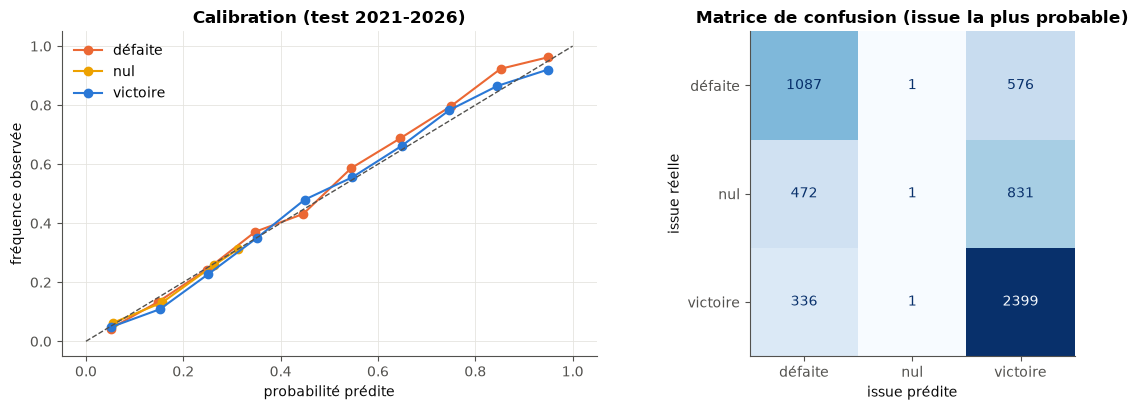

In [24]:
P_te = proba_issues(l1_te, l2_te, RHO)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for j, (nom, coul) in enumerate([("défaite", ORANGE), ("nul", JAUNE), ("victoire", BLEU)]):
    p, o = P_te[:, j], (y_te == j)
    bins = pd.cut(p, np.linspace(0, 1, 11))
    cal = pd.DataFrame({"p": p, "o": o}).groupby(bins, observed=True).agg(p=("p", "mean"), o=("o", "mean"), n=("o", "size"))
    cal = cal[cal.n >= 30]
    ax[0].plot(cal.p, cal.o, "o-", color=coul, label=nom)
ax[0].plot([0, 1], [0, 1], "--", color=GRIS, lw=1)
ax[0].set(title="Calibration (test 2021-2026)", xlabel="probabilité prédite", ylabel="fréquence observée"); ax[0].legend(frameon=False)

from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_te, P_te.argmax(1), display_labels=["défaite", "nul", "victoire"],
                                        ax=ax[1], cmap="Blues", colorbar=False)
ax[1].set(title="Matrice de confusion (issue la plus probable)", xlabel="issue prédite", ylabel="issue réelle"); ax[1].grid(False)
plt.tight_layout(); plt.show()

**Lecture**
- Les courbes de calibration suivent la diagonale : quand le modèle annonce 60 %, l'événement arrive environ 60 % du temps. Les probabilités sont **fiables**, et c'est ce qui compte pour simuler un tournoi.
- La matrice de confusion montre le revers de l'accuracy : le nul n'est **jamais** l'issue la plus probable, car sa probabilité dépasse rarement 30 %. Les 1 300 nuls du test sont donc tous « mal classés », alors que le modèle leur donne une probabilité correcte.

## 6.3 Sur les matchs qui ressemblent à une Coupe du monde

Le test mélange des amicaux et des qualifications déséquilibrées (Espagne – Malte…). On isole les matchs les plus proches de notre cible : **compétitifs, sur terrain neutre**.

In [25]:
sel = ((test.competitif == 1) & (test.neutre == 1)).values
print(f"{sel.sum()} matchs compétitifs sur terrain neutre dans le test")
pd.DataFrame([scores("LR (3 variables) — notebook", modeles_orig["LR (3 variables)"].predict_proba(test[VARS_ORIG])[sel], y_te[sel]),
              scores("Gradient Boosting réglé", hgb.predict_proba(test[VARS])[sel], y_te[sel]),
              scores("Poisson + Dixon-Coles", P_te[sel], y_te[sel])]).set_index("modèle").round(4)

1043 matchs compétitifs sur terrain neutre dans le test


,accuracy,log-loss,RPS,% nuls prédits
modèle,,,,
LR (3 variables) — notebook,0.6079,0.8805,0.1673,0.0
Gradient Boosting réglé,0.6069,0.8823,0.1676,0.0
Poisson + Dixon-Coles,0.6021,0.8787,0.1676,0.0


**Lecture** : sur ces 1 043 matchs, les trois modèles sont **à égalité** (RPS ≈ 0,167). L'évaluation classique ne permet pas de les départager : il faut un autre juge, la vraie Coupe du monde.

## [Éval]

Section 7 — Seconde évaluation, sur les 104 matchs réels de la Coupe du monde 2026 et sur 10 000 simulations du tournoi.

---
# 7. Confrontation à la réalité : la Coupe du monde 2026

C'est le moment de sortir les 104 matchs mis de côté en section 1.2.

## 7.1 Ce qui s'est réellement passé

In [26]:
def vainqueur(r):
    if r.home_score != r.away_score:
        return r.home_team if r.home_score > r.away_score else r.away_team
    s = shootouts[(shootouts.date == r.date) & (shootouts.home_team == r.home_team) & (shootouts.away_team == r.away_team)]
    return s.winner.iloc[0]

reel["phase"] = ["Groupes"] * 72 + ["16es"] * 16 + ["8es"] * 8 + ["Quarts"] * 4 + ["Demies"] * 2 + ["3e place", "Finale"]
reel["y"] = cible(reel.home_score, reel.away_score)
ko = reel[reel.phase != "Groupes"].copy()
ko["qualifié"] = [vainqueur(r) for r in ko.itertuples()]

ETAPES = ["Groupes", "16es", "8es", "Quarts", "Demies", "Finale", "Champion"]
etape_reelle = {t: "Groupes" for t in WC_TEAMS}
for ph, suivante in [("16es", "16es"), ("8es", "8es"), ("Quarts", "Quarts"), ("Demies", "Demies"), ("Finale", "Finale")]:
    for r in ko[ko.phase == ph].itertuples():
        etape_reelle[r.home_team] = etape_reelle[r.away_team] = suivante
finale = ko[ko.phase == "Finale"].iloc[0]
etape_reelle[finale.qualifié] = "Champion"

print(f"Champion : {finale.qualifié} | finale : {finale.home_team} {finale.home_score}-{finale.away_score} {finale.away_team}")
print("Demi-finalistes :", sorted(t for t, e in etape_reelle.items() if ETAPES.index(e) >= ETAPES.index("Demies")))
print(f"Issues des 104 matchs : {np.mean(reel.y == 2):.0%} victoires équipe 1, {np.mean(reel.y == 1):.0%} nuls, {np.mean(reel.y == 0):.0%} défaites "
      f"| {int((ko.home_score == ko.away_score).sum())} séances de tirs au but")
ko[["phase", "date", "home_team", "home_score", "away_score", "away_team", "qualifié"]].tail(8)

Champion : Spain | finale : Spain 1-0 Argentina
Demi-finalistes : ['Argentina', 'England', 'France', 'Spain']
Issues des 104 matchs : 47% victoires équipe 1, 23% nuls, 30% défaites | 4 séances de tirs au but


,phase,date,home_team,home_score,away_score,away_team,qualifié
96,Quarts,2026-07-09,France,2,0,Morocco,France
97,Quarts,2026-07-10,Spain,2,1,Belgium,Spain
98,Quarts,2026-07-11,Norway,1,2,England,England
99,Quarts,2026-07-11,Argentina,3,1,Switzerland,Argentina
100,Demies,2026-07-14,France,0,2,Spain,Spain
101,Demies,2026-07-15,England,1,2,Argentina,Argentina
102,3e place,2026-07-18,France,4,6,England,England
103,Finale,2026-07-19,Spain,1,0,Argentina,Spain


**Lecture** : l'**Espagne**, n°1 du classement Elo au coup d'envoi, est championne : 1-0 en finale contre l'**Argentine**, n°2. Les 4 demi-finalistes (Espagne, Argentine, France, Angleterre) sont **exactement les 4 premiers du classement Elo**. C'est un tournoi plutôt « logique », un point à garder en tête pour lire la suite.

## 7.2 Match par match : qui avait vu juste ?

On compare 4 modèles sur les 104 matchs, dans deux situations :
- **Prévision figée** : toutes les notes sont gelées au 11 juin. C'est la vraie prédiction d'avant tournoi, celle du notebook.
- **Prévision mise à jour** : avant chaque match, l'Elo et la forme intègrent les matchs déjà joués du tournoi. C'est ce que ferait un modèle utilisé « en direct ».

Pour les matchs à élimination directe, on évalue le résultat après prolongation (un nul = tirs au but).

| Modèle | Description |
|---|---|
| **Notebook d'origine** | LR 3 variables, notes Elo **+ ajustement « facteurs »** (version d'origine), avantage hôte de +40 |
| **Elo seul (LR)** | même LR, sans ajustement, terrain selon le calendrier |
| **Poisson + DC** | notre modèle de buts, notes Elo seules |
| **Poisson + DC + facteurs** | notre modèle de buts avec l'ajustement « facteurs » |

In [27]:
def etat_fige(h, a, neutral):
    "Variables d'avant-match avec l'état gelé au 11 juin."
    e = ETAT
    return dict(home=h, away=a, Rh=e.note(h), Ra=e.note(a), ha=0 if neutral else HOME_ADV, tournament="FIFA World Cup",
                forme_h=e.moy(e.pts, h), forme_a=e.moy(e.pts, a), bp_h=e.moy(e.bp, h), bc_h=e.moy(e.bc, h),
                bp_a=e.moy(e.bp, a), bc_a=e.moy(e.bc, a), n_h=e.n[h], n_a=e.n[a], hs=0, as_=0)

fige = ajouter_variables(pd.DataFrame([etat_fige(r.home_team, r.away_team, r.neutral) for r in reel.itertuples()]))
fige["y"] = reel.y.values

# Mise à jour : on rejoue l'Elo sur historique + tournoi et on garde l'état d'avant chaque match de CM
tout = pd.concat([historique, results_raw[results_raw.date.between(WC2026_START, WC2026_END)]]).sort_values("date", kind="stable")
am_tout, _ = calcul_elo(tout)
direct = ajouter_variables(am_tout[(am_tout.tournament == "FIFA World Cup") & (am_tout.date >= WC2026_START)].reset_index(drop=True))
assert (direct.home.values == reel.home_team.values).all()

lr_orig = modeles_orig["LR (3 variables)"]
def P_notebook(d, adj, host_edge=True):
    Rh = d.Rh + d.home.map(adj).fillna(0); Ra = d.Ra + d.away.map(adj).fillna(0)
    ha = (d.home.isin(HOSTS) * 40 - d.away.isin(HOSTS) * 40) if host_edge else d.ha
    X = pd.DataFrame({"ecart_brut": Rh - Ra, "ha": ha, "elo_moyen": (Rh + Ra) / 2})
    return lr_orig.predict_proba(X[VARS_ORIG])

def P_poisson(d, adj=None):
    d = d.copy()
    if adj: d["Rh"] = d.Rh + d.home.map(adj).fillna(0); d["Ra"] = d.Ra + d.away.map(adj).fillna(0)
    l1, l2 = lambdas(d)
    return proba_issues(l1, l2, RHO)

PREDS = {}
for mode, d in [("figée", fige), ("mise à jour", direct)]:
    PREDS[(mode, "Notebook d'origine")] = P_notebook(d, ADJ_ORIG)
    PREDS[(mode, "Elo seul (LR)")] = P_notebook(d, {}, host_edge=False)
    PREDS[(mode, "Poisson + DC")] = P_poisson(d)
    PREDS[(mode, "Poisson + DC + facteurs")] = P_poisson(d, ADJ)
freq = np.tile(np.bincount(y_tr) / len(y_tr), (104, 1))

lignes = []
for (mode, nom), P in PREDS.items():
    for portee, sl in [("104 matchs", slice(None)), ("72 de poule", slice(0, 72)), ("32 à élimination", slice(72, 104))]:
        s = scores(nom, P[sl], reel.y.values[sl]); s.update(prévision=mode, matchs=portee); lignes.append(s)
for portee, sl in [("104 matchs", slice(None)), ("72 de poule", slice(0, 72)), ("32 à élimination", slice(72, 104))]:
    s = scores("Référence : fréquences", freq[sl], reel.y.values[sl]); s.update(prévision="—", matchs=portee); lignes.append(s)
reel_scores = pd.DataFrame(lignes)
reel_scores[reel_scores.matchs == "104 matchs"].set_index(["prévision", "modèle"]).drop(columns="matchs").round(4)

accuracy  log-loss     RPS  % nuls prédits
prévision   modèle                                                             
figée       Notebook d'origine         0.6538    0.8298  0.1535          0.0000
            Elo seul (LR)              0.6731    0.8522  0.1601          0.0000
            Poisson + DC               0.6827    0.8462  0.1585          0.0000
            Poisson + DC + facteurs    0.6731    0.8221  0.1505          0.0000
mise à jour Notebook d'origine         0.6538    0.8363  0.1556          0.0096
            Elo seul (LR)              0.6346    0.8600  0.1627          0.0000
            Poisson + DC               0.6635    0.8589  0.1627          0.0000
            Poisson + DC + facteurs    0.6731    0.8352  0.1549          0.0000
—           Référence : fréquences     0.4712    1.0540  0.2293          0.0000

In [28]:
reel_scores.pivot_table(index=["prévision", "modèle"], columns="matchs", values="RPS").round(4)

matchs                               104 matchs  32 à élimination  72 de poule
prévision   modèle                                                            
figée       Elo seul (LR)                0.1601            0.1471       0.1659
            Notebook d'origine           0.1535            0.1369       0.1609
            Poisson + DC                 0.1585            0.1455       0.1642
            Poisson + DC + facteurs      0.1505            0.1347       0.1575
mise à jour Elo seul (LR)                0.1627            0.1511       0.1678
            Notebook d'origine           0.1556            0.1390       0.1630
            Poisson + DC                 0.1627            0.1560       0.1656
            Poisson + DC + facteurs      0.1549            0.1450       0.1593
—           Référence : fréquences       0.2293            0.2463       0.2217

**Lecture**
- Tous les modèles font **beaucoup mieux que la référence** (RPS 0,15-0,16 contre 0,23), avec 65 à 68 % de bonnes issues. C'est plus que sur le test 2021-2026 (61 %), car un tournoi à 48 équipes compte beaucoup de matchs déséquilibrés.
- **Les facteurs font la différence.** Avec la même LR, le notebook (Elo + facteurs) bat l'« Elo seul » : 0,1535 contre 0,1601. Avec notre modèle de buts : 0,1505 avec facteurs contre 0,1585 sans. La qualité de l'effectif apporte une information **que l'Elo n'a pas**.
- **Notre modèle final** (Poisson + DC + facteurs) est le meilleur sur les 104 matchs (0,1505), sur les matchs de poule comme en élimination directe.
- **Surprise** : mettre à jour les notes pendant le tournoi **dégrade** les prédictions, pour tous les modèles. Avec K = 60, un seul match de Coupe du monde fait beaucoup bouger l'Elo, alors qu'il apporte surtout du **bruit**. Pour un tournoi court, la prévision d'avant-tournoi est plus solide.

## 7.3 Les écarts sont-ils significatifs ?

104 matchs, c'est **peu**. Un seul match surprise peut faire bouger les métriques. Pour mesurer cette incertitude, on fait un **bootstrap** : on tire 5 000 fois 104 matchs au hasard (avec remise) parmi les 104, et on regarde l'intervalle dans lequel tombe l'écart de RPS entre deux modèles.

In [29]:
rng = np.random.default_rng(SEED)
yv = reel.y.values
def rps_par_match(P, y):
    O = np.eye(3)[y]; return np.sum((np.cumsum(P, 1) - np.cumsum(O, 1))[:, :2] ** 2, axis=1) / 2
ref = rps_par_match(PREDS[("figée", "Notebook d'origine")], yv)
idx = rng.integers(0, 104, size=(5000, 104))
lignes = []
for nom in ["Elo seul (LR)", "Poisson + DC", "Poisson + DC + facteurs"]:
    diff = rps_par_match(PREDS[("figée", nom)], yv) - ref
    b = diff[idx].mean(axis=1)
    lignes.append({"modèle comparé au notebook (prévision figée)": nom, "écart de RPS": diff.mean(),
                   "IC 95 % bas": np.percentile(b, 2.5), "IC 95 % haut": np.percentile(b, 97.5),
                   "P(meilleur que le notebook)": np.mean(b < 0)})
pd.DataFrame(lignes).set_index("modèle comparé au notebook (prévision figée)").round(4)

,écart de RPS,IC 95 % bas,IC 95 % haut,P(meilleur que le notebook)
modèle comparé au notebook (prévision figée),,,,
Elo seul (LR),0.0066,0.0000,0.0132,0.0248
Poisson + DC,0.0050,-0.0039,0.0138,0.1378
Poisson + DC + facteurs,-0.0030,-0.0089,0.0030,0.8438


**Lecture**
- **Elo seul** contre notebook : l'écart (+0,0066) est positif dans 97,5 % des tirages. Retirer les facteurs dégrade **nettement** la prédiction : l'apport de la couche « facteurs » est probablement réel.
- **Notre modèle final** contre notebook : −0,0030 en moyenne, meilleur dans 84 % des tirages, mais l'intervalle contient 0. Sur un seul tournoi, l'amélioration est **plausible mais pas démontrée**. Il faudrait l'évaluer sur d'autres compétitions (Euro, Copa América…) pour conclure.

## 7.4 Les plus grosses surprises du tournoi

In [30]:
P = PREDS[("figée", "Poisson + DC")]
surprise = reel[["phase", "home_team", "home_score", "away_score", "away_team"]].copy()
surprise["P(issue réelle)"] = P[np.arange(104), yv]
surprise["P(victoire 1 / nul / victoire 2)"] = [f"{p[2]:.0%} / {p[1]:.0%} / {p[0]:.0%}" for p in P]
surprise.nsmallest(8, "P(issue réelle)").style.format({"P(issue réelle)": "{:.1%}"}).hide(axis="index")

phase,home_team,home_score,away_score,away_team,P(issue réelle),P(victoire 1 / nul / victoire 2)
Groupes,Spain,0,0,Cape Verde,8.1%,90% / 8% / 2%
Groupes,England,0,0,Ghana,14.4%,81% / 14% / 5%
Groupes,Ivory Coast,1,0,Ecuador,16.5%,16% / 28% / 56%
Groupes,South Africa,1,0,South Korea,17.5%,17% / 27% / 56%
Groupes,Ecuador,0,0,Curaçao,17.6%,76% / 18% / 7%
Groupes,Qatar,1,1,Switzerland,18.1%,7% / 18% / 74%
Groupes,Ghana,1,0,Panama,18.5%,19% / 26% / 55%
Groupes,Canada,1,1,Bosnia and Herzegovina,21.2%,70% / 21% / 9%


**Lecture** : les grosses surprises sont surtout des **favoris tenus en échec**. Espagne – Cap-Vert 0-0 n'avait que 8 % de chances d'arriver, Angleterre – Ghana 0-0 14 %. En poule, 27,8 % des matchs ont fini nuls, contre 23 % en moyenne historique. C'est la principale faiblesse de tous les modèles : ils sous-estiment les nuls des favoris, peut-être parce qu'une équipe déjà qualifiée ou prudente en début de tournoi joue moins pour gagner.

## 7.5 Le tournoi entier : 10 000 simulations, avant et après correction

On relance la simulation Monte-Carlo du notebook (même règle de tableau final approchée) avec deux moteurs :
- **Notebook d'origine** : Poisson « polyfit », notes ajustées par les facteurs d'origine, avantage hôte de +40, tirs au but gagnés par le favori Elo ;
- **Notre modèle** : Poisson + Dixon-Coles avec les notes **ajustées par les facteurs** (le meilleur modèle de la section 7.2), avantage du terrain réel pour les hôtes (+100 quand ils jouent chez eux, comme le prévoit le calendrier), tirs au but à 50/50 ;
- **Notre modèle sans facteurs** : le même, avec les notes Elo seules, pour isoler l'apport des facteurs.

Puis on compare les probabilités de chaque équipe d'atteindre chaque tour avec ce qui s'est **réellement** passé.

In [31]:
N_SIMS = 10_000

class Moteur:
    "Tire des scores pour un match entre h et a. Les distributions sont mises en cache par affiche."
    def __init__(self, nom, cdf_fn, tab_fn):
        self.nom, self.cdf_fn, self.tab_fn, self.cache = nom, cdf_fn, tab_fn, {}
    def cdf(self, h, a):
        if (h, a) not in self.cache: self.cache[(h, a)] = self.cdf_fn(h, a)
        return self.cache[(h, a)]
    def scores(self, h, a, n, rng):
        idx = np.searchsorted(self.cdf(h, a), rng.random(n))
        idx = np.minimum(idx, (BUTS_MAX + 1) ** 2 - 1)
        return idx // (BUTS_MAX + 1), idx % (BUTS_MAX + 1)
    def tab(self, h, a, rng): return self.tab_fn(h, a, rng)

def note_orig(t): return ETAT.note(t) + ADJ_ORIG.get(t, 0)
def cdf_notebook(h, a):
    he = (40 if h in HOSTS else 0) - (40 if a in HOSTS else 0)
    l1, l2 = exp_goals_orig(note_orig(h) - note_orig(a) + he), exp_goals_orig(note_orig(a) - note_orig(h) - he)
    return np.cumsum(np.outer(poisson.pmf(np.arange(BUTS_MAX + 1), l1), poisson.pmf(np.arange(BUTS_MAX + 1), l2)).ravel() / 1)
def tab_notebook(h, a, rng):
    return h if rng.random() < 1 / (1 + 10 ** (-(note_orig(h) - note_orig(a)) / 400)) else a

def cdf_poisson(adj):
    def cdf(h, a):
        # l'hôte joue chez lui (comme dans le vrai calendrier) ; sinon terrain neutre
        if a in HOSTS and h not in HOSTS:
            M = matrice_poisson(a, h, False, adj).T          # calculée du point de vue de l'hôte, puis remise dans l'ordre (h, a)
        else:
            M = matrice_poisson(h, a, not (h in HOSTS or a in HOSTS), adj)
        return np.cumsum(M.ravel())
    return cdf
def matrice_poisson(h, a, neutral, adj):
    d = pd.DataFrame([etat_fige(h, a, neutral)])
    d["Rh"] += adj.get(h, 0); d["Ra"] += adj.get(a, 0)
    l1, l2 = lambdas(ajouter_variables(d))
    return matrice_scores(l1[0], l2[0], RHO)
def tab_pile_face(h, a, rng): return h if rng.random() < 0.5 else a

MOTEURS = [Moteur("Notebook d'origine", cdf_notebook, tab_notebook),
           Moteur("Notre modèle", cdf_poisson(ADJ), tab_pile_face),
           Moteur("Notre modèle sans facteurs", cdf_poisson({}), tab_pile_face)]

def simuler(moteur, n=N_SIMS, seed=SEED):
    rng = np.random.default_rng(seed)
    # --- phase de groupes, vectorisée sur les n simulations
    pts = {t: np.zeros(n) for t in WC_TEAMS}; diff = {t: np.zeros(n) for t in WC_TEAMS}; bp = {t: np.zeros(n) for t in WC_TEAMS}
    for g, ts in GROUPS.items():
        for h, a in itertools.combinations(ts, 2):
            x, y = moteur.scores(h, a, n, rng)
            pts[h] += 3 * (x > y) + (x == y); pts[a] += 3 * (y > x) + (x == y)
            diff[h] += x - y; diff[a] += y - x; bp[h] += x; bp[a] += y
    atteint = {t: np.zeros(n, dtype=int) for t in WC_TEAMS}      # indice dans ETAPES
    for s in range(n):
        classement = {g: sorted(ts, key=lambda t: (pts[t][s], diff[t][s], bp[t][s], rng.random()), reverse=True) for g, ts in GROUPS.items()}
        premiers = [c[0] for c in classement.values()]; seconds = [c[1] for c in classement.values()]
        troisiemes = sorted([c[2] for c in classement.values()], key=lambda t: (pts[t][s], diff[t][s], bp[t][s], rng.random()), reverse=True)[:8]
        qualifies = premiers + seconds + troisiemes
        rang = {**{t: 0 for t in premiers}, **{t: 1 for t in seconds}, **{t: 2 for t in troisiemes}}
        tete = sorted(qualifies, key=lambda t: (rang[t], -ETAT.note(t)))
        tour = [(tete[i], tete[31 - i]) for i in range(16)]
        niveau = 1
        for t in qualifies: atteint[t][s] = 1
        while True:
            gagnants = []
            for h, a in tour:
                x, y = moteur.scores(h, a, 1, rng)
                gagnants.append(h if x[0] > y[0] else a if y[0] > x[0] else moteur.tab(h, a, rng))
            niveau += 1
            for w in gagnants: atteint[w][s] = niveau
            if len(gagnants) == 1: break
            tour = [(gagnants[i], gagnants[i + 1]) for i in range(0, len(gagnants), 2)]
    return pd.DataFrame({ETAPES[k]: {t: np.mean(atteint[t] >= k) for t in WC_TEAMS} for k in range(1, 7)})

SIMS = {}
for m in MOTEURS:
    t0 = time.perf_counter(); SIMS[m.nom] = simuler(m)
    print(f"{m.nom} : {N_SIMS:,} tournois simulés en {time.perf_counter() - t0:.0f} s")

Notebook d'origine : 10,000 tournois simulés en 2 s


Notre modèle : 10,000 tournois simulés en 13 s


Notre modèle sans facteurs : 10,000 tournois simulés en 14 s


In [32]:
reel_idx = {t: ETAPES.index(e) for t, e in etape_reelle.items()}
lignes = []
for k in range(1, 7):
    o = np.array([reel_idx[t] >= k for t in WC_TEAMS])
    ligne = {"tour atteint": ETAPES[k], "équipes réelles": int(o.sum())}
    for nom, S in SIMS.items():
        ligne[f"Brier — {nom}"] = np.mean((S.loc[WC_TEAMS, ETAPES[k]].values - o) ** 2)
    lignes.append(ligne)
brier = pd.DataFrame(lignes).set_index("tour atteint")
print("Score de Brier par tour (écart quadratique moyen entre probabilité et réalité, plus bas = mieux)")
display(brier.round(4))

dernier_carre = [t for t in WC_TEAMS if reel_idx[t] >= ETAPES.index("Demies")]
cmp = pd.concat({nom: S.loc[dernier_carre, ["Demies", "Finale", "Champion"]] for nom, S in SIMS.items()}, axis=1)
cmp.insert(0, "réalité", [etape_reelle[t] for t in dernier_carre])
print("\nProbabilités données aux 4 demi-finalistes réels")
cmp.style.format({c: "{:.1%}" for c in cmp.columns if c[0] != "réalité"})

Score de Brier par tour (écart quadratique moyen entre probabilité et réalité, plus bas = mieux)


,équipes réelles,Brier — Notebook d'origine,Brier — Notre modèle,Brier — Notre modèle sans facteurs
tour atteint,,,,
16es,32,0.1783,0.1734,0.1772
8es,16,0.1341,0.1207,0.1254
Quarts,8,0.0954,0.0942,0.0986
Demies,4,0.0485,0.0524,0.0529
Finale,2,0.0252,0.0267,0.0267
Champion,1,0.0139,0.0141,0.0147



Probabilités données aux 4 demi-finalistes réels


**Lecture**
- On retrouve l'ordre de grandeur publié par l'auteur (Espagne 22,6 % dans son notebook, 21,9 % dans notre reproduction ; l'écart vient de l'aléa et de la version des données).
- **Premiers tours (16es, 8es, quarts)** : notre modèle est le meilleur. Il a notamment mieux vu les **pays hôtes** : Mexique, États-Unis et Canada ont tous atteint les 8es de finale. Notre modèle leur applique l'avantage du terrain réel (+100), le notebook seulement +40.
- **Derniers tours** : le notebook est un peu meilleur. Il est plus confiant envers les grands favoris, grâce à son avantage aux tirs au but et à sa Poisson qui accentue les écarts, et les 4 grands favoris ont tous atteint le dernier carré. Sur **un seul** tournoi « logique », cette confiance est récompensée. Ce serait l'inverse lors d'un tournoi à surprises.
- Les écarts de Brier restent faibles : il n'y a qu'un champion et deux finalistes.

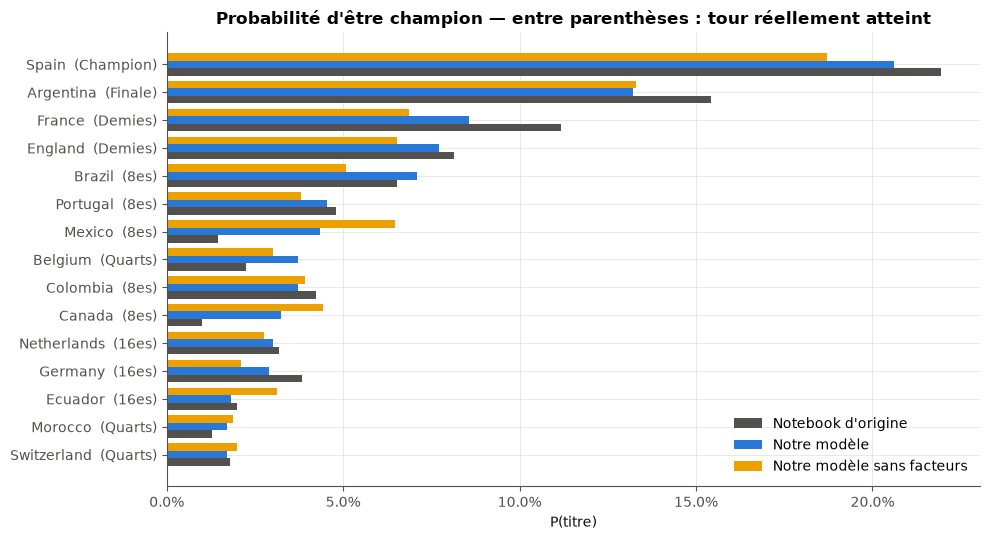

In [33]:
fig, ax = plt.subplots(figsize=(10, 5.5))
top = SIMS["Notre modèle"].Champion.sort_values(ascending=False).head(15).index[::-1]
y = np.arange(len(top))
for k, (nom, coul) in enumerate([("Notebook d'origine", GRIS), ("Notre modèle", BLEU), ("Notre modèle sans facteurs", JAUNE)]):
    ax.barh(y + (k - 1) * 0.27, SIMS[nom].loc[top, "Champion"] * 100, height=0.27, color=coul, label=nom)
ax.set_yticks(y); ax.set_yticklabels([f"{t}  ({etape_reelle[t]})" for t in top])
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set(title="Probabilité d'être champion — entre parenthèses : tour réellement atteint", xlabel="P(titre)")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

## 7.6 La couche « facteurs » aide-t-elle ?

L'ajustement par les facteurs (qualité de l'effectif, ligues, expérience…) est un **jugement d'expert** de l'auteur. Il n'a jamais été validé, puisque FC 26 n'existe que pour 2026. On peut enfin le tester : on fait varier le plafond de l'ajustement (0 = Elo seul, 60 = choix de l'auteur, jusqu'à 150) et on mesure le RPS sur les 104 matchs réels, en prévision figée.

In [34]:
lignes = []
for cap in [0, 30, 60, 90, 120, 150]:
    adj = ajustement(feat, cap=cap) if cap else {}
    lignes.append({"plafond (points Elo)": cap, "RPS Poisson + DC + facteurs (104 matchs)": rps(P_poisson(fige, adj), yv),
                   "RPS — 72 de poule": rps(P_poisson(fige.iloc[:72], adj), yv[:72]),
                   "RPS — 32 à élimination": rps(P_poisson(fige.iloc[72:], adj), yv[72:])})
display(pd.DataFrame(lignes).set_index("plafond (points Elo)").round(4))

# Fuite d'information ? On retire la seule variable Transfermarkt (exp_caps, extraite après le tournoi)
sans_tm = {k: w for k, w in W_FACTEURS.items() if k != "exp_caps"}
print(f"RPS avec tous les facteurs : {rps(P_poisson(fige, ADJ), yv):.4f} | "
      f"sans la variable Transfermarkt (exp_caps) : {rps(P_poisson(fige, ajustement(feat, poids=sans_tm)), yv):.4f}")

,RPS Poisson + DC + facteurs (104 matchs),RPS — 72 de poule,RPS — 32 à élimination
plafond (points Elo),,,
0,0.1585,0.1642,0.1455
30,0.1532,0.1594,0.1392
60,0.1505,0.1575,0.1347
90,0.1503,0.1574,0.1343
120,0.1503,0.1574,0.1343
150,0.1503,0.1574,0.1343


RPS avec tous les facteurs : 0.1505 | sans la variable Transfermarkt (exp_caps) : 0.1507


**Lecture**
- L'ajustement par les facteurs améliore le RPS de 0,1585 à 0,1505. Presque tout le gain est obtenu **avant 60 points** : le plafond choisi à la main par l'auteur était bien vu. Au-delà, plus rien ne change, car aucun ajustement ne dépasse environ 90 points.
- Le gain est le plus fort en **élimination directe** (0,1455 → 0,1347), là où se rencontrent les meilleures équipes : entre équipes de même Elo, la qualité de l'effectif départage.
- **Fuite d'information** : sans la variable Transfermarkt extraite après le tournoi, le résultat ne change presque pas. Le gain vient des notes FC 26, publiées en octobre 2025, donc **sans fuite**.

## 7.7 Probabilités et score prédit : cohérence des modèles

Dans le notebook, les probabilités des matchs de poule viennent du **classifieur** (LR), mais la **simulation** du tournoi tire les scores avec la **Poisson polyfit**. Ces deux modèles donnent-ils les mêmes probabilités ?

In [35]:
P_lr = P_notebook(fige.iloc[:72], ADJ_ORIG)
P_po = np.array([proba_issues([exp_goals_orig(note_orig(h) - note_orig(a) + (40 if h in HOSTS else 0) - (40 if a in HOSTS else 0))],
                              [exp_goals_orig(note_orig(a) - note_orig(h) - (40 if h in HOSTS else 0) + (40 if a in HOSTS else 0))], 0)[0]
                 for h, a in zip(fige.home[:72], fige.away[:72])])
ecart = np.abs(P_lr - P_po)
print(f"Notebook — écart entre classifieur et Poisson de simulation sur P(victoire, nul, défaite) : moyen {ecart.mean():.1%}, maximal {ecart.max():.1%}")
print(f"P(nul) moyenne : classifieur {P_lr[:, 1].mean():.1%} | Poisson de simulation {P_po[:, 1].mean():.1%} | réalité (72 matchs de poule) {np.mean(yv[:72] == 1):.1%}")

def score_le_plus_probable(M):
    i, j = np.unravel_index(M.argmax(), M.shape); return int(i), int(j)
def score_conditionnel(M):
    "Score le plus probable PARMI les scores de l'issue la plus probable."
    issues = {"victoire": np.tril(np.ones_like(M), -1), "nul": np.eye(len(M)), "défaite": np.triu(np.ones_like(M), 1)}
    best = max(issues, key=lambda k: (M * issues[k]).sum())
    return best, score_le_plus_probable(M * issues[best])

n_nul = 0
for h, a, neu in zip(fige.home[:72], fige.away[:72], fige.neutre[:72]):
    M = matrice_poisson(h, a, bool(neu), ADJ)
    i, j = score_le_plus_probable(M)
    n_nul += (i == j) and np.trace(M) < max(np.tril(M, -1).sum(), np.triu(M, 1).sum())
print(f"Notre modèle : {n_nul} matchs de poule sur 72 où le score le plus probable est un nul alors que le nul n'est pas l'issue la plus probable")
M = matrice_poisson("Spain", "France", True, ADJ)
print("Espagne – France : score le plus probable", score_le_plus_probable(M), "| issue la plus probable et son score :", score_conditionnel(M))

Notebook — écart entre classifieur et Poisson de simulation sur P(victoire, nul, défaite) : moyen 3.6%, maximal 8.1%
P(nul) moyenne : classifieur 23.6% | Poisson de simulation 21.2% | réalité (72 matchs de poule) 27.8%


Notre modèle : 29 matchs de poule sur 72 où le score le plus probable est un nul alors que le nul n'est pas l'issue la plus probable
Espagne – France : score le plus probable (1, 1) | issue la plus probable et son score : ('victoire', (1, 0))


**Lecture**
- ⚠️ Dans le notebook, les deux modèles ne racontent **pas tout à fait la même histoire** : les probabilités affichées pour les matchs de poule (classifieur) et celles qui servent à simuler le tournoi (Poisson) diffèrent de 3,6 points en moyenne, jusqu'à 8 points. La simulation prévoit aussi moins de nuls. Notre modèle utilise **une seule** matrice de scores pour tout.
- Le « score le plus probable » est **souvent 1-1**, même quand une équipe est favorite. Ce n'est pas une erreur : la victoire se répartit sur de nombreux scores (1-0, 2-0, 2-1…), alors que le nul se concentre sur 0-0 et 1-1. Mais c'est trompeur à afficher. Pour l'API, on affichera le **score le plus probable parmi les scores de l'issue la plus probable** (fonction `score_conditionnel`).

## [Déploiement]

Section 8 — Sauvegarde des artefacts nécessaires à une future API.

---
# 8. Déploiement — préparation

Le déploiement (API dans un conteneur Docker) sera fait dans un second temps. On prépare dès maintenant les **artefacts** dont l'API aura besoin. Elle n'aura **pas** à recalculer 150 ans d'Elo : il lui suffit de l'état gelé des équipes et du modèle de buts.

| Fichier | Contenu |
|---|---|
| `artefacts/modele_buts.joblib` | pipeline scikit-learn (normalisation + régression de Poisson) |
| `artefacts/etat_equipes.csv` | pour chaque équipe : Elo, ajustement « facteurs », forme, buts marqués/encaissés, matchs joués (au 11 juin 2026) |
| `artefacts/config.json` | ρ de Dixon-Coles, avantage du terrain, liste des variables, groupes |
| `artefacts/probabilites_tournoi.csv` | les probabilités de la simulation (notre modèle) |

In [36]:
import joblib
joblib.dump(modele_buts, ART / "modele_buts.joblib")
etat_equipes = pd.DataFrame([{"team": t, "elo": ETAT.note(t), "ajustement_facteurs": ADJ.get(t, 0.0), "forme": ETAT.moy(ETAT.pts, t),
                              "buts_pour": ETAT.moy(ETAT.bp, t), "buts_contre": ETAT.moy(ETAT.bc, t), "matchs": ETAT.n[t]}
                             for t in ETAT.elo]).sort_values("elo", ascending=False)
etat_equipes.to_csv(ART / "etat_equipes.csv", index=False)
json.dump({"rho": RHO, "home_adv": HOME_ADV, "buts_max": BUTS_MAX, "variables": VARS_BUTS, "groupes": GROUPS,
           "hotes": sorted(HOSTS), "date_gel": str(WC2026_START.date())}, open(ART / "config.json", "w"), indent=2, ensure_ascii=False)
SIMS["Notre modèle"].sort_values("Champion", ascending=False).to_csv(ART / "probabilites_tournoi.csv")

# Vérification : on recharge le modèle et on prédit un match comme le fera l'API
m = joblib.load(ART / "modele_buts.joblib")
d = pd.DataFrame([etat_fige("Spain", "France", True)]); d["Rh"] += ADJ["Spain"]; d["Ra"] += ADJ["France"]
e1, e2 = vue_equipe(ajouter_variables(d)); l1, l2 = m.predict(e1[VARS_BUTS])[0], m.predict(e2[VARS_BUTS])[0]
M = matrice_scores(l1, l2, RHO)
print(f"Espagne – France : buts attendus {l1:.2f} – {l2:.2f} | victoire {np.tril(M, -1).sum():.0%}, nul {np.trace(M):.0%}, "
      f"défaite {np.triu(M, 1).sum():.0%} | issue et score prédits : {score_conditionnel(M)}")
print("Artefacts :", sorted(p.name for p in ART.iterdir()))

Espagne – France : buts attendus 1.52 – 1.02 | victoire 48%, nul 28%, défaite 24% | issue et score prédits : ('victoire', (1, 0))
Artefacts : ['config.json', 'etat_equipes.csv', 'modele_buts.joblib', 'probabilites_tournoi.csv']


## [Conclusion]

Section 9 — Corrections apportées au notebook d'origine et conclusion des sections 1 à 9.

---
# 9. Bilan

## 9.1 Les corrections apportées au notebook d'origine

| # | Problème | Conséquence | Correction |
|---|---|---|---|
| 1 | `LogisticRegression(multi_class=…)` | Le notebook **plante** avec scikit-learn ≥ 1.8 | Paramètre retiré (multinomial par défaut) |
| 2 | Variable `sc` pour le `StandardScaler` | Confusion avec le `SparkContext` ; normalisation gérée à la main | Pipeline scikit-learn |
| 3 | Deux modèles différents pour les probabilités (classifieur) et la simulation (Poisson) | Probabilités affichées ≠ probabilités simulées | Un seul modèle de buts : Poisson + Dixon-Coles |
| 4 | Poisson ajustée par régression linéaire sur `log(buts + 0,5)` | Buts attendus biaisés | Vraie régression de Poisson (maximum de vraisemblance) |
| 5 | Filtre des ligues féminines incomplet (`GPFBL` oubliée) | Effet minime (1 joueuse) | Filtre complété |
| 6 | Tirs au but gagnés par le favori Elo | Chances des favoris surestimées en élimination directe | 50/50, conforme aux 690 séances historiques |
| 7 | Tri par date non stable | L'ordre des matchs d'un même jour peut changer | `sort_values(kind="stable")` |
| 8 | Score affiché = score le plus probable (souvent 1-1) | Paraît contredire le favori annoncé | Score le plus probable **de l'issue prédite** |
| 9 | Poids et plafond des « facteurs » choisis à la main, jamais validés | Ajustement arbitraire | Mesuré sur la vraie CM (section 7.6) : il **aide** |
| ✓ | *Expérience calculée avec des joueurs retraités ?* | *Vérifié : non, leurs sélections ne sont pas renseignées* | *Aucune correction nécessaire* |
| — | Données Transfermarkt extraites après le tournoi (notre téléchargement) | Fuite possible sur les sélections | Limitée à la couche « facteurs », évaluée à part |

## 9.2 Conclusion

**Sur la démarche**
- Le processus complet a été déroulé sur des données « petites » (≈ 50 000 matchs), en **pandas et scikit-learn**, sans Spark : Data → EDA → Pré-traitement → Transformation → ML → Évaluation, avec les artefacts prêts pour le déploiement.
- L'étape décisive n'est pas le choix de l'algorithme, c'est la **transformation** : l'Elo condense 150 ans de résultats en une note par équipe, et la qualité des effectifs apporte l'information qui lui manque.
- Avoir les vrais résultats change tout : l'évaluation sur un **jeu de test historique** ne départageait pas les modèles (RPS ≈ 0,166 pour tous). L'évaluation **sur la vraie Coupe du monde** montre ce qui compte vraiment.

**Sur les résultats**

| Constat | Chiffres |
|---|---|
| Le notebook d'origine était **bon** | RPS 0,1535 sur les 104 matchs, contre 0,2293 pour la référence ; Espagne favorite (22 %) et finale Espagne – Argentine annoncée |
| Complexifier le ML **n'aide pas** | 3 → 9 variables, Random Forest, XGBoost, boosting réglé : gain ≤ 0,001 de RPS sur le test |
| L'information sur les **effectifs aide** | RPS 0,1585 → 0,1505 grâce aux facteurs, sans fuite (vient de FC 26) |
| **Notre modèle final** est le meilleur sur les matchs | 0,1505, contre 0,1535 pour le notebook, mais l'écart n'est pas significatif sur un seul tournoi (meilleur dans 84 % des tirages bootstrap) |
| Mettre à jour pendant le tournoi **dégrade** | sur tous les modèles, à cause du bruit de quelques matchs |
| Les tirs au but sont une **loterie** | le favori gagne 53 % des séances, pas 65 % comme le suppose le notebook |

**Limites**
- **Un seul tournoi** (104 matchs) : les écarts entre bons modèles restent dans la marge d'incertitude.
- Les **nuls** restent sous-estimés (27,8 % en poule contre environ 23 % prédits).
- Le tableau final est une **approximation** de la règle FIFA (495 combinaisons pour les meilleurs troisièmes), comme dans le notebook.
- Les poids des facteurs restent choisis à la main : on a montré qu'ils aident, pas qu'ils sont optimaux. Les apprendre demanderait des notes FC des éditions précédentes (FC 24, FC 25…) pour les tournois passés.

**Suite** : le déploiement. Une API (FastAPI) dans un conteneur Docker chargera les artefacts de la section 8 et répondra à `/predict?home=Spain&away=France` avec les probabilités, les buts attendus et le score prédit.

---
# 10. Complément — les mêmes données traitées avec PySpark

Le notebook Kaggle d'origine n'utilise pas PySpark, et les sections 1 à 9 non plus : avec quelques Mo de données, pandas suffit. Cette section complète le notebook en refaisant le traitement des données avec PySpark, sur les mêmes fichiers et avec les mêmes règles.

| Étape | Sous-section | Ce qui est refait avec PySpark | Vérification |
|---|---|---|---|
| **Environnement** | 10.1 | Démarrage d'une session Spark locale | — |
| **Data** | 10.2 | Lecture des CSV avec un schéma explicite, gel des données au 11 juin 2026 | mêmes volumes qu'en 1.2 |
| **Prétraitement** | 10.3 | Valeurs manquantes, doublons, anciens noms de pays (jointure *broadcast*) | même table qu'en 3.1 |
| **EDA** | 10.4 | Agrégations avec l'API DataFrame et avec Spark SQL, jointure avec les tirs au but | mêmes chiffres qu'en 2.1, 2.2 et 2.4 |
| **Transformation** | 10.5 | Variables d'avant-match (forme, buts marqués et encaissés) avec des fonctions de fenêtre | identique à `artefacts/etat_equipes.csv` |
| **Éval** | 10.6 | Comparaison pandas / Spark : mêmes résultats ? quel temps de calcul ? | — |
| **Conclusion** | 10.7 | Ce que Spark apporte, ou non, sur de petites données | — |

Pour chaque résultat, je compare Spark et pandas avec un `assert` : si les deux diffèrent, la cellule s'arrête sur une erreur.

**Ce qui n'est pas refait avec Spark** : le classement Elo (section 4.1) et les modèles (section 5). L'Elo se calcule match après match : la note d'une équipe dépend de la note de son adversaire, elle-même issue de tous ses matchs précédents. Ce calcul est séquentiel : on ne peut pas le découper en partitions indépendantes, donc Spark ne l'accélère pas.

## [Environnement]

**10.1 Démarrage de Spark.** Même configuration que les TP1 et TP2 : Spark 3.5 en mode `local[*]` (les cœurs du Mac jouent le rôle des machines d'un cluster) et Java 11 installé dans `~/hadoop_tp` par le TP1. Le nombre de partitions de *shuffle* est ramené de 200 à 8 : avec 50 000 lignes, 200 partitions ne créeraient que des tâches presque vides.

In [37]:
import glob
os.environ["JAVA_HOME"] = sorted(glob.glob(str(Path.home() / "hadoop_tp" / "jdk-11*")))[-1] + "/Contents/Home"
os.environ["PYSPARK_PYTHON"] = sys.executable            # même interpréteur pour le driver et les workers
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession, Window, functions as F, types as T

t0 = time.perf_counter()
spark = (SparkSession.builder.master("local[*]").appName("TP3 Small - complement PySpark")
         .config("spark.driver.memory", "2g")
         .config("spark.sql.shuffle.partitions", "8")        # 200 par défaut : beaucoup trop pour quelques Mo
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print(f"Spark {spark.version} | master = {spark.sparkContext.master} | parallélisme = {spark.sparkContext.defaultParallelism} "
      f"| session démarrée en {time.perf_counter() - t0:.1f} s")

Spark 3.5.9 | master = local[*] | parallélisme = 10 | session démarrée en 2.8 s


## [Data]

**10.2 Ingestion.** On lit trois des fichiers de la section 1 (`results.csv`, `shootouts.csv`, `former_names.csv`) avec un schéma explicite. Par rapport à `inferSchema`, Spark n'a pas à lire le fichier une première fois pour deviner les types. Et avec le mode `FAILFAST`, la lecture s'arrête si une ligne ne respecte pas le schéma, au lieu de mettre des valeurs nulles sans prévenir.

On applique ensuite le même gel au 11 juin 2026 qu'en section 1.2 : l'historique s'arrête la veille du coup d'envoi, les 104 matchs du tournoi sont mis de côté.

In [38]:
# Schémas explicites : Spark ne relit pas le fichier pour deviner les types, et une ligne non conforme lève une erreur
SCHEMA_RESULTS = T.StructType([
    T.StructField("date", T.DateType()),          T.StructField("home_team", T.StringType()),
    T.StructField("away_team", T.StringType()),   T.StructField("home_score", T.IntegerType()),
    T.StructField("away_score", T.IntegerType()), T.StructField("tournament", T.StringType()),
    T.StructField("city", T.StringType()),        T.StructField("country", T.StringType()),
    T.StructField("neutral", T.BooleanType()),
])
SCHEMA_SHOOTOUTS = T.StructType([
    T.StructField("date", T.DateType()),        T.StructField("home_team", T.StringType()),
    T.StructField("away_team", T.StringType()), T.StructField("winner", T.StringType()),
    T.StructField("first_shooter", T.StringType()),
])
SCHEMA_FORMER = T.StructType([
    T.StructField("current", T.StringType()),     T.StructField("former", T.StringType()),
    T.StructField("start_date", T.DateType()),    T.StructField("end_date", T.DateType()),
])

def lire_spark(nom, schema):
    return spark.read.csv(str(DATA / nom), header=True, schema=schema, mode="FAILFAST")

# "ordre" = position de la ligne dans le fichier : il départage les matchs joués le même jour (tri stable, cf. 3.1)
results_sp      = lire_spark("results.csv", SCHEMA_RESULTS).withColumn("ordre", F.monotonically_increasing_id())
shootouts_sp    = lire_spark("shootouts.csv", SCHEMA_SHOOTOUTS)
former_names_sp = lire_spark("former_names.csv", SCHEMA_FORMER)

# Même gel qu'en 1.2 : l'historique s'arrête la veille du coup d'envoi
DEBUT_CM, FIN_CM = (F.lit(str(d.date())).cast("date") for d in (WC2026_START, WC2026_END))
historique_sp = results_sp.filter(F.col("date") < DEBUT_CM).cache()
reel_sp = results_sp.filter((F.col("tournament") == "FIFA World Cup") & F.col("date").between(DEBUT_CM, FIN_CM))

results_sp.printSchema()
n_hist_sp, n_reel_sp = historique_sp.count(), reel_sp.count()
print(f"Historique Spark : {n_hist_sp:,} matchs | Réel CM 2026 : {n_reel_sp} matchs | partitions : {historique_sp.rdd.getNumPartitions()}")
print(f"Historique pandas (1.2) : {len(historique_raw):,} matchs | Réel : {len(reel)} matchs")
assert n_hist_sp == len(historique_raw) and n_reel_sp == len(reel)
print("✓ Mêmes volumes que le chargement pandas")

root
 |-- date: date (nullable = true)
 |-- home_team: string (nullable = true)
 |-- away_team: string (nullable = true)
 |-- home_score: integer (nullable = true)
 |-- away_score: integer (nullable = true)
 |-- tournament: string (nullable = true)
 |-- city: string (nullable = true)
 |-- country: string (nullable = true)
 |-- neutral: boolean (nullable = true)
 |-- ordre: long (nullable = false)



Historique Spark : 49,475 matchs | Réel CM 2026 : 104 matchs | partitions : 1
Historique pandas (1.2) : 49,475 matchs | Réel : 104 matchs
✓ Mêmes volumes que le chargement pandas


**Lecture**
- Spark retrouve exactement les volumes de pandas : 49 475 matchs d'historique et 104 matchs de Coupe du monde.
- Le fichier tient dans une seule partition : il est bien plus petit qu'un bloc de 128 Mo. Il n'y a donc aucun parallélisme à la lecture, comme pour Hadoop dans le TP1.
- La colonne `ordre` (position de la ligne dans le fichier) remplace l'index pandas : un DataFrame Spark n'a pas d'ordre garanti, il faut donc le stocker dans une colonne pour pouvoir trier de façon stable (correction n°7 de la section 9.1).

## [Prétraitement]

**10.3 Contrôle qualité et harmonisation.** Les mêmes vérifications qu'en section 3, écrites avec Spark :

1. **valeurs manquantes** : comptées pour toutes les colonnes en une seule passe ;
2. **doublons** : un contrôle que le notebook pandas ne faisait pas ;
3. **anciens noms de pays** (`Dahomey` → `Benin`…) : jointure avec `former_names.csv`. La table est minuscule, on la diffuse à tous les *workers* avec `F.broadcast`, ce qui évite un *shuffle* ;
4. mise en cache de la table nettoyée, réutilisée par toutes les cellules suivantes.

In [39]:
# 1) Valeurs manquantes : une seule passe sur les données pour toutes les colonnes
colonnes = [c for c in historique_sp.columns if c != "ordre"]
print("Valeurs manquantes par colonne :")
historique_sp.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in colonnes]).show()

# 2) Doublons : un même match (date, équipes) ne doit apparaître qu'une fois
n_doublons = n_hist_sp - historique_sp.dropDuplicates(["date", "home_team", "away_team"]).count()
print(f"Matchs en double : {n_doublons}")

# 3) Anciens noms de pays : jointure avec former_names.csv (petite table, diffusée à tous les workers : broadcast)
def harmoniser(df, colonne):
    "Remplace un ancien nom de pays par son nom actuel si le match a eu lieu pendant la période de l'ancien nom."
    f = F.broadcast(former_names_sp)
    condition = (df[colonne] == f["former"]) & df["date"].between(f["start_date"], f["end_date"])
    return (df.join(f, condition, "left")
              .withColumn(colonne, F.coalesce(F.col("current"), F.col(colonne)))
              .drop("current", "former", "start_date", "end_date"))

matchs_sp = harmoniser(harmoniser(historique_sp, "home_team"), "away_team")
n_renommes = (matchs_sp.join(historique_sp.select("ordre", F.col("home_team").alias("h0"), F.col("away_team").alias("a0")), "ordre")
                       .filter((F.col("home_team") != F.col("h0")) | (F.col("away_team") != F.col("a0"))).count())
print(f"Matchs dont une équipe a été renommée : {n_renommes}")

# 4) Scores manquants écartés (aucun ici), puis mise en cache : cette table sert à toute la suite
matchs_sp = matchs_sp.dropna(subset=["home_score", "away_score"]).cache()
assert matchs_sp.count() == len(historique)
print(f"Table nettoyée : {matchs_sp.count():,} matchs, comme en pandas (3.1)")

Valeurs manquantes par colonne :


+----+---------+---------+----------+----------+----------+----+-------+-------+
|date|home_team|away_team|home_score|away_score|tournament|city|country|neutral|
+----+---------+---------+----------+----------+----------+----+-------+-------+
|   0|        0|        0|         0|         0|         0|   0|      0|      0|
+----+---------+---------+----------+----------+----------+----+-------+-------+



Matchs en double : 1


Matchs dont une équipe a été renommée : 0


Table nettoyée : 49,475 matchs, comme en pandas (3.1)


**Lecture**
- **Aucune valeur manquante** et aucun ancien nom à corriger : `results.csv` est déjà harmonisé, comme le montrait la section 3.2.
- Spark signale 1 match en double (même date, mêmes équipes), que le notebook pandas ne recherchait pas. Il s'agit de Tahiti – Nouvelle-Calédonie, le 17 février 1974, présent avec deux scores (2-1 et 1-2) : deux rencontres le même jour, ou une erreur de saisie de la source. On le conserve : la table doit rester identique à celle de pandas (49 475 matchs) pour que les comparaisons qui suivent aient un sens, et un match sur 49 475 ne change aucun résultat.

## [EDA]

**10.4 Analyse exploratoire distribuée.** On refait trois analyses de la section 2 avec les deux façons d'interroger un DataFrame Spark :

- l'API DataFrame (`groupBy`, `agg`) pour les matchs par an et les issues selon le terrain ;
- **Spark SQL** pour les compétitions et pour une jointure avec les séances de tirs au but.

Comme au TP2, l'agrégation est faite dans Spark, et seul le petit résultat (quelques lignes) est converti en pandas pour l'affichage.

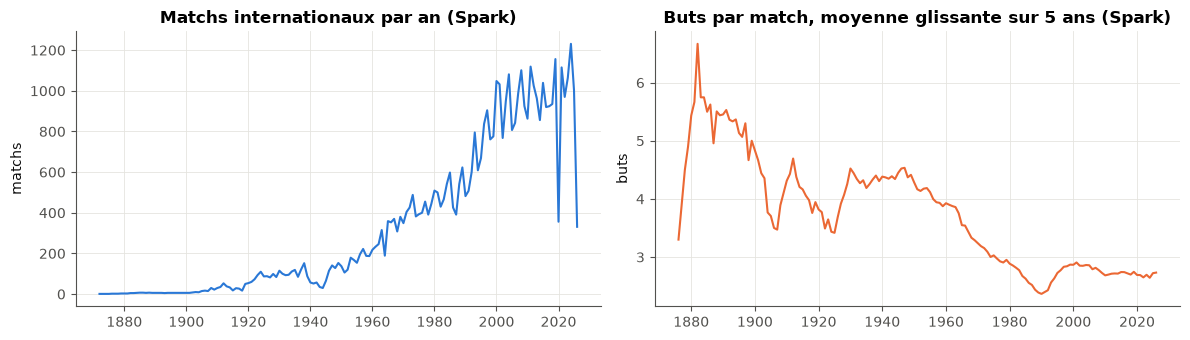

Buts par match depuis 2000 : Spark 2.7554 | pandas 2.7554


In [40]:
# L'agrégation est faite par Spark ; seul le petit résultat (une ligne par année) passe dans pandas pour le tracé
par_an = (matchs_sp.withColumn("annee", F.year("date"))
          .groupBy("annee")
          .agg(F.count("*").alias("matchs"), F.avg(F.col("home_score") + F.col("away_score")).alias("buts"))
          .orderBy("annee").toPandas().set_index("annee"))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
par_an.matchs.plot(ax=ax[0], color=BLEU)
ax[0].set(title="Matchs internationaux par an (Spark)", xlabel="", ylabel="matchs")
par_an.buts.rolling(5).mean().plot(ax=ax[1], color=ORANGE)
ax[1].set(title="Buts par match, moyenne glissante sur 5 ans (Spark)", xlabel="", ylabel="buts")
plt.tight_layout(); plt.show()

buts_2000_sp = (matchs_sp.filter(F.year("date") >= 2000)
                .agg(F.avg(F.col("home_score") + F.col("away_score"))).first()[0])
buts_2000_pd = (h[h.annee >= 2000].buts).mean()
print(f"Buts par match depuis 2000 : Spark {buts_2000_sp:.4f} | pandas {buts_2000_pd:.4f}")
assert abs(buts_2000_sp - buts_2000_pd) < 1e-9

In [41]:
# --- API DataFrame : les trois issues d'un match, dans trois contextes
def issues_sp(df, contexte):
    return df.agg(F.lit(contexte).alias("contexte"),
                  F.avg((F.col("home_score") > F.col("away_score")).cast("int")).alias("Victoire équipe 1"),
                  F.avg((F.col("home_score") == F.col("away_score")).cast("int")).alias("Nul"),
                  F.avg((F.col("home_score") < F.col("away_score")).cast("int")).alias("Victoire équipe 2"),
                  F.count("*").alias("matchs"))

recent_sp = matchs_sp.filter(F.col("date") >= "2000-01-01")
tab_sp = (issues_sp(recent_sp.filter(~F.col("neutral")), "À domicile")
          .unionByName(issues_sp(recent_sp.filter(F.col("neutral")), "Terrain neutre"))
          .unionByName(issues_sp(recent_sp.filter(F.col("tournament") == "FIFA World Cup"), "Coupe du monde (phase finale)"))
          .toPandas().set_index("contexte"))
print(tab_sp.round(3).to_string())

# Vérification : mêmes valeurs que le tableau pandas de la section 2.2
assert np.allclose(tab_sp.values.astype(float), tab.loc[tab_sp.index, tab_sp.columns].values.astype(float))
print("\n✓ Identique au tableau pandas de la section 2.2")

                               Victoire équipe 1    Nul  Victoire équipe 2  matchs
contexte                                                                          
À domicile                                 0.508  0.231              0.261   18139
Terrain neutre                             0.416  0.237              0.348    7270
Coupe du monde (phase finale)              0.435  0.229              0.336     384

✓ Identique au tableau pandas de la section 2.2


In [42]:
# --- Spark SQL : la même table, interrogée en SQL après l'avoir déclarée comme vue temporaire
matchs_sp.createOrReplaceTempView("matchs")
shootouts_sp.createOrReplaceTempView("tirs_au_but")

spark.sql("""
    SELECT tournament                                           AS competition,
           COUNT(*)                                             AS matchs,
           ROUND(AVG(home_score + away_score), 2)               AS buts_par_match,
           ROUND(100 * AVG(CAST(home_score = away_score AS INT)), 1) AS pct_nuls
    FROM matchs
    GROUP BY tournament
    ORDER BY matchs DESC
    LIMIT 12
""").show(truncate=False)

n_comp, part_amicaux = spark.sql("SELECT COUNT(DISTINCT tournament), AVG(CAST(tournament = 'Friendly' AS INT)) FROM matchs").first()
print(f"{n_comp} compétitions différentes ; amicaux = {part_amicaux:.0%} des matchs (pandas, section 2.4 : "
      f"{historique_raw.tournament.nunique()} et {(historique_raw.tournament == 'Friendly').mean():.0%})")

# Jointure : on rattache chaque séance de tirs au but à son match pour connaître la compétition
print("\nSéances de tirs au but : les compétitions les plus concernées, et l'équipe qui tire en premier gagne-t-elle plus souvent ?")
spark.sql("""
    SELECT m.tournament                                              AS competition,
           COUNT(*)                                                  AS seances,
           COUNT(t.first_shooter)                                    AS premier_tireur_connu,
           ROUND(100 * AVG(CASE WHEN t.first_shooter IS NOT NULL
                                THEN CAST(t.winner = t.first_shooter AS INT) END), 1) AS pct_victoire_premier_tireur
    FROM tirs_au_but t
    JOIN matchs m ON m.date = t.date AND m.home_team = t.home_team AND m.away_team = t.away_team
    GROUP BY m.tournament
    ORDER BY seances DESC
    LIMIT 8
""").show(truncate=False)

ligne = spark.sql("""
    SELECT COUNT(*), COUNT(first_shooter), AVG(CAST(winner = first_shooter AS INT))
    FROM tirs_au_but WHERE date < '2026-06-11'
""").first()
print(f"Avant le tournoi : {ligne[0]} séances, premier tireur connu pour {ligne[1]} ; il gagne {ligne[2]:.1%} de ces séances")

+------------------------------------+------+--------------+--------+
|competition                         |matchs|buts_par_match|pct_nuls|
+------------------------------------+------+--------------+--------+
|Friendly                            |18199 |2.88          |25.1    |
|FIFA World Cup qualification        |8771  |2.89          |21.1    |
|UEFA Euro qualification             |2824  |2.83          |19.6    |
|African Cup of Nations qualification|2339  |2.42          |24.5    |
|FIFA World Cup                      |964   |2.82          |22.2    |
|Copa América                        |869   |3.14          |21.6    |
|African Cup of Nations              |845   |2.38          |28.6    |
|AFC Asian Cup qualification         |829   |3.29          |16.5    |
|UEFA Nations League                 |658   |2.51          |25.1    |
|CECAFA Cup                          |620   |2.51          |23.7    |
|CFU Caribbean Cup qualification     |606   |3.51          |20.5    |
|Merdeka Tournament 

+------------------------------------+-------+--------------------+---------------------------+
|competition                         |seances|premier_tireur_connu|pct_victoire_premier_tireur|
+------------------------------------+-------+--------------------+---------------------------+
|COSAFA Cup                          |63     |3                   |33.3                       |
|Friendly                            |63     |0                   |NULL                       |
|African Cup of Nations              |47     |40                  |52.5                       |
|FIFA World Cup                      |35     |35                  |48.6                       |
|Copa América                        |33     |33                  |51.5                       |
|African Cup of Nations qualification|28     |0                   |NULL                       |
|AFC Asian Cup                       |27     |20                  |55.0                       |
|UEFA Euro                           |25

**Lecture**
- Les résultats sont identiques à ceux de pandas : 2,76 buts par match depuis 2000, 50,8 % de victoires à domicile contre 41,6 % sur terrain neutre, environ 23 % de nuls, 223 compétitions dont 37 % d'amicaux.
- **API DataFrame ou SQL** : les deux écritures passent par le même optimiseur (Catalyst), comme mesuré au TP2. Le choix est une question de lisibilité.
- **Tirs au but** : l'équipe qui tire en premier gagne 53,1 % des 260 séances où l'ordre est connu. L'écart avec 50 % est faible sur un si petit échantillon. Cela conforte le choix de la section 4.3 : traiter une séance comme un tirage quasi équilibré.

## [Transformation]

**10.5 Variables d'avant-match avec des fonctions de fenêtre.** En section 4.1, la « forme » d'une équipe (moyenne des points sur ses 10 derniers matchs), ses buts marqués et ses buts encaissés sont calculés par une boucle Python qui parcourt les matchs un par un. Avec Spark, on écrit le même calcul sans boucle :

1. on passe au format long : une ligne par équipe et par match ;
2. on définit une fenêtre (`Window`) par équipe, triée par date, qui couvre les 10 lignes précédentes : `rowsBetween(-10, -1)`. Le match courant est exclu, donc aucune information du futur n'entre dans la variable ;
3. on calcule l'état de chaque équipe au coup d'envoi et on le compare à l'artefact `etat_equipes.csv` produit par la boucle pandas.

In [43]:
# 1) Format « long » : une ligne par équipe et par match (au lieu d'une ligne par match avec deux équipes)
dom = matchs_sp.select("ordre", "date", F.col("home_team").alias("team"), F.col("away_team").alias("adversaire"),
                       F.col("home_score").alias("bp"), F.col("away_score").alias("bc"))
ext = matchs_sp.select("ordre", "date", F.col("away_team").alias("team"), F.col("home_team").alias("adversaire"),
                       F.col("away_score").alias("bp"), F.col("home_score").alias("bc"))
long_sp = (dom.unionByName(ext)
           .withColumn("pts", F.when(F.col("bp") > F.col("bc"), 1.0).when(F.col("bp") == F.col("bc"), 0.5).otherwise(0.0)))

# 2) Fenêtre glissante : pour chaque équipe, ses N_FORME matchs PRÉCÉDENTS (le match courant est exclu : pas de fuite)
ordre_equipe = Window.partitionBy("team").orderBy("date", "ordre")
w_avant = ordre_equipe.rowsBetween(-N_FORME, -1)
avant_match_sp = (long_sp
    .withColumn("n_avant", F.count("*").over(ordre_equipe.rowsBetween(Window.unboundedPreceding, -1)))
    .withColumn("forme_avant", F.round(F.avg("pts").over(w_avant), 3))
    .withColumn("bp_avant", F.round(F.avg("bp").over(w_avant), 2))
    .withColumn("bc_avant", F.round(F.avg("bc").over(w_avant), 2)))

print(f"Format long : {long_sp.count():,} lignes (2 × {matchs_sp.count():,} matchs)")
print("Les 5 derniers matchs de l'Espagne avant le tournoi, avec les variables connues AVANT chaque match :")
(avant_match_sp.filter(F.col("team") == "Spain").orderBy(F.desc("date"), F.desc("ordre")).limit(5)
               .select("date", "adversaire", "bp", "bc", "pts", "n_avant", "forme_avant", "bp_avant", "bc_avant").show())

# 3) État de chaque équipe au coup d'envoi : moyenne sur ses N_FORME derniers matchs (cette fois, dernier match inclus)
rang = F.row_number().over(Window.partitionBy("team").orderBy(F.desc("date"), F.desc("ordre")))
total = F.count("*").over(Window.partitionBy("team"))
etat_sp = (long_sp.withColumn("rang", rang).withColumn("matchs", total)
           .filter(F.col("rang") <= N_FORME)
           .groupBy("team", "matchs")
           .agg(F.avg("pts").alias("forme"), F.avg("bp").alias("buts_pour"), F.avg("bc").alias("buts_contre"))
           .toPandas().set_index("team"))

# 4) Vérification : l'artefact de la section 8 a été produit par la boucle Python de la section 4.1
etat_pd = pd.read_csv(ART / "etat_equipes.csv").set_index("team")
colonnes_etat = ["forme", "buts_pour", "buts_contre", "matchs"]
assert set(etat_sp.index) == set(etat_pd.index)
assert np.allclose(etat_sp.loc[etat_pd.index, colonnes_etat].values.astype(float), etat_pd[colonnes_etat].values.astype(float))
print(f"✓ Forme, buts marqués, buts encaissés et nombre de matchs identiques à artefacts/etat_equipes.csv pour les {len(etat_pd)} équipes")
print(etat_sp.loc[etat_pd.index[:5], colonnes_etat].round(2).to_string())

Format long : 98,950 lignes (2 × 49,475 matchs)
Les 5 derniers matchs de l'Espagne avant le tournoi, avec les variables connues AVANT chaque match :


+----------+----------+---+---+---+-------+-----------+--------+--------+
|      date|adversaire| bp| bc|pts|n_avant|forme_avant|bp_avant|bc_avant|
+----------+----------+---+---+---+-------+-----------+--------+--------+
|2026-06-08|      Peru|  3|  1|1.0|    782|        0.8|     2.7|     0.5|
|2026-06-04|      Iraq|  1|  1|0.5|    781|       0.85|     3.1|     0.8|
|2026-03-31|     Egypt|  0|  0|0.5|    780|       0.85|     3.4|     1.1|
|2026-03-27|    Serbia|  3|  0|1.0|    779|        0.8|     3.3|     1.3|
|2025-11-18|    Turkey|  2|  2|0.5|    778|       0.85|     3.4|     1.3|
+----------+----------+---+---+---+-------+-----------+--------+--------+



✓ Forme, buts marqués, buts encaissés et nombre de matchs identiques à artefacts/etat_equipes.csv pour les 337 équipes
           forme  buts_pour  buts_contre  matchs
team                                            
Spain       0.85        2.8          0.4     783
Argentina   0.85        2.5          0.3    1067
France      0.85        2.5          0.9     935
England     0.85        2.4          0.2    1090
Brazil      0.65        2.5          1.1    1059


**Lecture**
- Les fonctions de fenêtre redonnent exactement les valeurs de la boucle Python pour les 337 équipes : forme, buts marqués, buts encaissés et nombre de matchs.
- Ce calcul se parallélise bien : chaque équipe est une partition indépendante de la fenêtre. Sur un cluster, les équipes seraient réparties entre les machines.
- **Limite** : l'Elo, lui, ne s'écrit pas avec une fenêtre. La mise à jour d'une équipe dépend de la note courante de son adversaire, donc de l'état de toutes les autres équipes au même instant. C'est pourquoi il reste calculé en Python (section 4.1).

## [Éval]

**10.6 Spark contre pandas : mêmes résultats ? quel temps de calcul ?** On évalue ici le traitement, pas un modèle. On exécute la même agrégation (par compétition : nombre de matchs, buts par match, part de nuls) avec les deux moteurs, dans deux situations : données déjà en mémoire, puis en repartant du fichier CSV.

In [44]:
import statistics

def mediane_ms(f, n=7):
    "Une exécution d'échauffement, puis la médiane de n mesures, en millisecondes."
    f(); durees = []
    for _ in range(n):
        t0 = time.perf_counter(); f(); durees.append(time.perf_counter() - t0)
    return 1000 * statistics.median(durees)

# Le même calcul dans les trois cas : par compétition, nombre de matchs, buts par match et part de nuls
def agg_pandas():
    d = historique.assign(buts=historique.home_score + historique.away_score, nul=historique.home_score == historique.away_score)
    return d.groupby("tournament").agg(matchs=("buts", "size"), buts=("buts", "mean"), nuls=("nul", "mean"))

def agg_spark(df):
    return (df.groupBy("tournament")
              .agg(F.count("*").alias("matchs"), F.avg(F.col("home_score") + F.col("away_score")).alias("buts"),
                   F.avg((F.col("home_score") == F.col("away_score")).cast("int")).alias("nuls")).collect())

def agg_pandas_csv():
    d = pd.read_csv(DATA / "results.csv", parse_dates=["date"])
    d = d[d.date < WC2026_START]
    d = d.assign(buts=d.home_score + d.away_score, nul=d.home_score == d.away_score)
    return d.groupby("tournament").agg(matchs=("buts", "size"), buts=("buts", "mean"), nuls=("nul", "mean"))

def agg_spark_csv():
    return agg_spark(lire_spark("results.csv", SCHEMA_RESULTS).filter(F.col("date") < DEBUT_CM))

# Les deux moteurs donnent-ils le même résultat ?
r_pd = agg_pandas()
r_sp = pd.DataFrame([r.asDict() for r in agg_spark(matchs_sp)]).set_index("tournament").loc[r_pd.index]
assert np.allclose(r_pd.values.astype(float), r_sp[r_pd.columns].values.astype(float))
print(f"✓ Résultats identiques sur les {len(r_pd)} compétitions\n")

bench_sp = pd.DataFrame({
    "pandas": [mediane_ms(agg_pandas), mediane_ms(agg_pandas_csv)],
    "Spark":  [mediane_ms(lambda: agg_spark(matchs_sp)), mediane_ms(agg_spark_csv)],
}, index=["données déjà en mémoire", "depuis le fichier CSV"])
bench_sp["Spark / pandas"] = bench_sp["Spark"] / bench_sp["pandas"]
print("Temps médian en millisecondes (7 mesures après échauffement) :")
print(bench_sp.round(1).to_string())

✓ Résultats identiques sur les 223 compétitions



Temps médian en millisecondes (7 mesures après échauffement) :
                         pandas  Spark  Spark / pandas
données déjà en mémoire     5.0   85.7            17.2
depuis le fichier CSV      66.2  164.9             2.5


**Lecture**
- Les deux moteurs donnent les mêmes résultats sur les 223 compétitions.
- Sur ce volume, Spark est plus lent que pandas : environ 17 fois sur des données en mémoire (86 ms contre 5 ms) et 2,5 fois en repartant du CSV (165 ms contre 66 ms). Ces temps varient un peu d'une exécution à l'autre. Il faut y ajouter le démarrage de la session (environ 3 s).
- La raison est celle du TP1 : chaque requête Spark a un coût fixe (planification, lancement des tâches, échanges entre Python et la machine Java), qui domine tant que les données tiennent dans une partition. Ce coût ne devient rentable qu'à grand volume : dans la partie `Big/` de ce TP, à 6,5 millions de lignes, c'est Spark qui est 4 à 12 fois plus rapide que pandas.

## [Conclusion]

**10.7 Ce qu'apporte PySpark sur ces données**

| Question | Réponse |
|---|---|
| Le traitement des données peut-il être fait avec PySpark ? | **Oui** : ingestion, contrôle qualité, EDA et variables d'avant-match sont refaits avec Spark et donnent exactement les résultats de pandas (vérifié par `assert`). |
| Est-ce plus rapide ? | **Non** : 2,5 à 17 fois plus lent sur 49 475 matchs, à cause des coûts fixes de Spark. |
| Est-ce plus lisible ? | Pour les variables glissantes, oui : une fonction de fenêtre remplace une boucle et ses structures de données. |
| Tout se transpose-t-il ? | Non : l'Elo est séquentiel et reste en Python. |
| Quand passer à Spark ? | Quand les données ne tiennent plus en mémoire sur une machine. Le code de cette section tournerait alors sans modification sur un cluster. |

À retenir : le choix de l'outil dépend du volume. Ici, pandas est le bon outil et Spark sert de vérification. La partie `Big/` traite le cas inverse.

In [45]:
spark.stop()
print("Session Spark arrêtée")

Session Spark arrêtée
